# Palm Vein Recognition — V2 (PyTorch + GPU)

## Architecture Overview

| Property | Value |
|----------|-------|
| Framework | PyTorch |
| GPU | NVIDIA GeForce RTX 5070 |
| Dataset | FYODB — 150 classes, palm vein infrared |
| Fusion | Score-Level (Softmax Averaging) |
| Models | 11 (10 pretrained + 1 custom PVCNN) |
| TTA | Test-Time Augmentation validation included |

### What's new in V2 vs V1

- **PyTorch** — GPU works natively on RTX 5070
- **CLAHE preprocessing** — enhances vein contrast in infrared images
- **11 diverse models** — covering different architectural families
- **Score-level fusion** — uses softmax probabilities, more accurate than majority vote
- **Custom PVCNN** — designed specifically for near-infrared palm vein images
- **TTA validation** — test-time augmentation for robust evaluation
- **Skip-if-trained** — each model cell checks for saved weights before training
- **Preprocessed images saved** — CLAHE enhanced images stored to disk

## Cell 1 · Install Dependencies & Force GPU

> **Run once, restart kernel, then continue from Cell 2.**

| Step | Action | Why |
|------|--------|-----|
| 1 | Install PyTorch and detect CUDA via torch | Most reliable GPU detection on Windows |
| 2 | Install project dependencies | CV, augmentation, metrics libraries |
| 3 | Verify GPU | Confirms RTX 5070 is accessible |

In [1]:
import subprocess, sys
def pip(*args): subprocess.check_call([sys.executable,'-m','pip','install',*args,'-q'])

# ── Step 1: PyTorch + CUDA detection ─────────────────────────────────────────
try:
    import torch
    print(f'PyTorch {torch.__version__} already installed | CUDA: {torch.cuda.is_available()}')
    if torch.cuda.is_available(): print(f'GPU: {torch.cuda.get_device_name(0)}')
except ImportError:
    try:
        smi=subprocess.check_output(['nvidia-smi'],stderr=subprocess.DEVNULL).decode()
        url='https://download.pytorch.org/whl/cu126' if 'CUDA Version: 12' in smi else 'https://download.pytorch.org/whl/cu118'
        pip('torch==2.6.0','torchvision==0.21.0','torchaudio==2.6.0','--index-url',url)
    except Exception:
        pip('torch==2.6.0','torchvision==0.21.0','torchaudio==2.6.0')
    import torch

# ── Step 2: Project dependencies ──────────────────────────────────────────────
pip('opencv-python','Pillow','numpy','pandas','scikit-learn',
    'matplotlib','seaborn','tqdm','albumentations','timm')

print('Done. Restart kernel then run from Cell 2.')


PyTorch 2.12.0.dev20260408+cu128 already installed | CUDA: True
GPU: NVIDIA GeForce RTX 5070
Done. Restart kernel then run from Cell 2.


## Cell 2 · Imports & GPU Configuration

| Library | Role |
|---------|------|
| `torch` / `torchvision` | Deep learning framework + pretrained models |
| `timm` | 800+ pretrained vision models (EfficientNet, ConvNeXt, RegNet) |
| `cv2` | CLAHE preprocessing and image enhancement |
| `albumentations` | Fast GPU-friendly augmentation pipeline |
| `sklearn` | Metrics — confusion matrix, classification report, ROC/AUC |

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as T
import torchvision.models as models
import timm

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from tqdm import tqdm
import os, json, time, glob, shutil

from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# ── GPU Configuration ─────────────────────────────────────────────────────────
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
    # Allow TF32 for faster matrix ops on Ampere/Ada/Blackwell
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True  # auto-tune conv algorithms

# ── Global Paths ──────────────────────────────────────────────────────────────
DATASET_PATH      = r'F:\Palm Vein Multimodel V2\Dataset FYO'
PREPROCESSED_PATH = r'F:\Palm Vein Multimodel V2\Dataset FYO Preprocessed'
OUTPUT_BASE       = 'Outputs/PalmVein_V2'
MODELS_DIR        = 'Saved Models/PalmVein_V2'

for d in [OUTPUT_BASE, MODELS_DIR,
          f'{OUTPUT_BASE}/curves', f'{OUTPUT_BASE}/confusion',
          f'{OUTPUT_BASE}/roc',    f'{OUTPUT_BASE}/reports',
          f'{OUTPUT_BASE}/preprocessing']:
    os.makedirs(d, exist_ok=True)

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('\nAll directories created. Ready.')


Device: cuda
GPU: NVIDIA GeForce RTX 5070
VRAM: 12.8 GB

All directories created. Ready.


In [9]:
import gc
gc.collect()
torch.cuda.empty_cache()
print(f'Free VRAM: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB')

Free VRAM: 11.6 GB


## Cell 3 · CLAHE Preprocessing — Enhance & Save

Palm vein images captured in near-infrared have low contrast between vein and tissue.  
**CLAHE (Contrast Limited Adaptive Histogram Equalization)** enhances local contrast, making vein patterns more distinct for the CNN.

### Preprocessing pipeline

| Step | Operation | Effect |
|------|-----------|--------|
| 1 | Convert RGB → grayscale | Extracts the single meaningful channel from infrared image |
| 2 | Apply CLAHE | Enhances vein contrast locally without over-amplifying noise |
| 3 | Replicate to 3 channels | Pretrained models expect 3-channel input |
| 4 | Save as PNG | Preprocessed images stored for reproducibility |

> This cell runs once — if preprocessed folder already exists it skips processing.

Preprocessed dataset already exists at F:\Palm Vein Multimodel V2\Dataset FYO Preprocessed
Total images: 6000


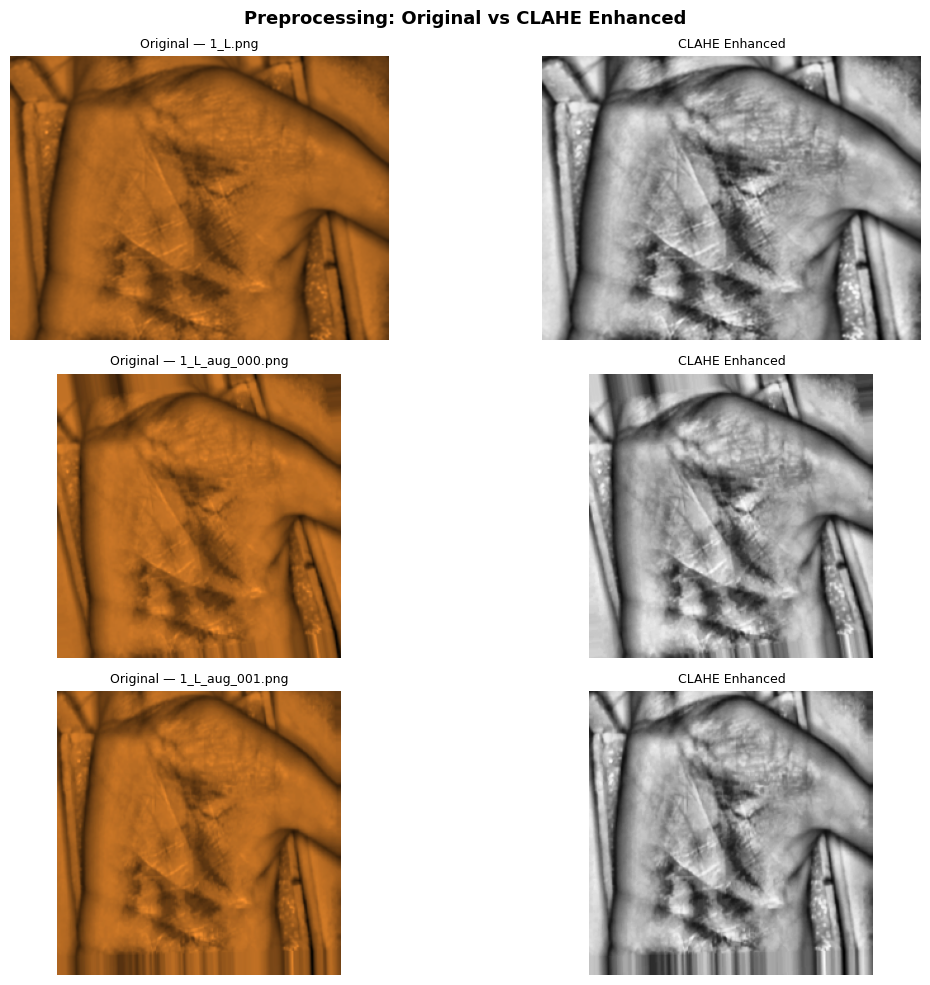

Saved: Outputs/PalmVein_V2/preprocessing/clahe_comparison.png


In [11]:
def apply_clahe_preprocessing(src_root, dst_root, clip_limit=2.0, tile_grid=(8,8)):
    """
    Apply CLAHE to all images in src_root and save to dst_root.
    Preserves the class folder structure exactly.
    clip_limit: higher = more contrast enhancement, more noise risk
    tile_grid: local region size for adaptive equalization
    """
    src_root = Path(src_root)
    dst_root = Path(dst_root)

    # Check if already preprocessed
    if dst_root.exists() and len(list(dst_root.rglob('*.png'))) > 100:
        print(f'Preprocessed dataset already exists at {dst_root}')
        print(f'Total images: {len(list(dst_root.rglob("*.png")))}')
        return

    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)

    img_extensions = {'.png', '.jpg', '.jpeg', '.bmp'}
    all_imgs = [p for p in src_root.rglob('*') if p.suffix.lower() in img_extensions]

    print(f'Processing {len(all_imgs)} images...')
    skipped = 0

    for img_path in tqdm(all_imgs, desc='CLAHE preprocessing'):
        # Preserve folder structure
        rel_path  = img_path.relative_to(src_root)
        dst_path  = dst_root / rel_path.with_suffix('.png')
        dst_path.parent.mkdir(parents=True, exist_ok=True)

        img = cv2.imread(str(img_path))
        if img is None:
            skipped += 1
            continue

        # Convert to grayscale — extracts the infrared vein information
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Apply CLAHE — enhances local vein contrast
        enhanced = clahe.apply(gray)

        # Replicate single channel to 3 channels for pretrained model compatibility
        rgb = cv2.merge([enhanced, enhanced, enhanced])

        cv2.imwrite(str(dst_path), rgb)

    print(f'Done. Processed: {len(all_imgs)-skipped} | Skipped: {skipped}')
    print(f'Saved to: {dst_root}')


# Run preprocessing
apply_clahe_preprocessing(DATASET_PATH, PREPROCESSED_PATH)


# ── Visualise preprocessing effect ────────────────────────────────────────────
src_samples = list(Path(DATASET_PATH).rglob('*.png'))[:3] + \
              list(Path(DATASET_PATH).rglob('*.jpg'))[:3]
src_samples = src_samples[:3]

if src_samples:
    fig, axes = plt.subplots(3, 2, figsize=(12, 10))
    clahe_vis = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))

    for idx, img_path in enumerate(src_samples):
        img  = cv2.imread(str(img_path))
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        enh  = clahe_vis.apply(gray)

        axes[idx,0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[idx,0].set_title(f'Original — {img_path.name}', fontsize=9)
        axes[idx,0].axis('off')

        axes[idx,1].imshow(enh, cmap='gray')
        axes[idx,1].set_title('CLAHE Enhanced', fontsize=9)
        axes[idx,1].axis('off')

    plt.suptitle('Preprocessing: Original vs CLAHE Enhanced', fontsize=13, fontweight='bold')
    plt.tight_layout()
    save_path = f'{OUTPUT_BASE}/preprocessing/clahe_comparison.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_path}')


## Cell 4 · Dataset & DataLoaders

Loads the **preprocessed** CLAHE-enhanced dataset and creates train/val/test splits.

### Augmentation strategy

| Augmentation | Parameter | Rationale |
|-------------|-----------|----------|
| RandomHorizontalFlip | p=0.5 | Palm can be imaged from either orientation |
| RandomRotation | ±15° | Camera angle variation |
| ColorJitter | brightness=0.2, contrast=0.2 | Lighting variation between sessions |
| RandomAffine | translate=0.1, scale=0.9-1.1 | Hand position variation |
| RandomErasing | p=0.1 | Simulates partial occlusion |
| Normalize | ImageNet stats | Required for pretrained model compatibility |

Test set uses only resize + normalize — no augmentation.

Total images:  6000
Total classes: 150
Sample classes: ['1', '10', '100', '101', '102', '103', '104', '105', '106', '107']

Train: 4200 | Val: 600 | Test: 1200
Train batches: 132 | Val batches: 19 | Test batches: 38


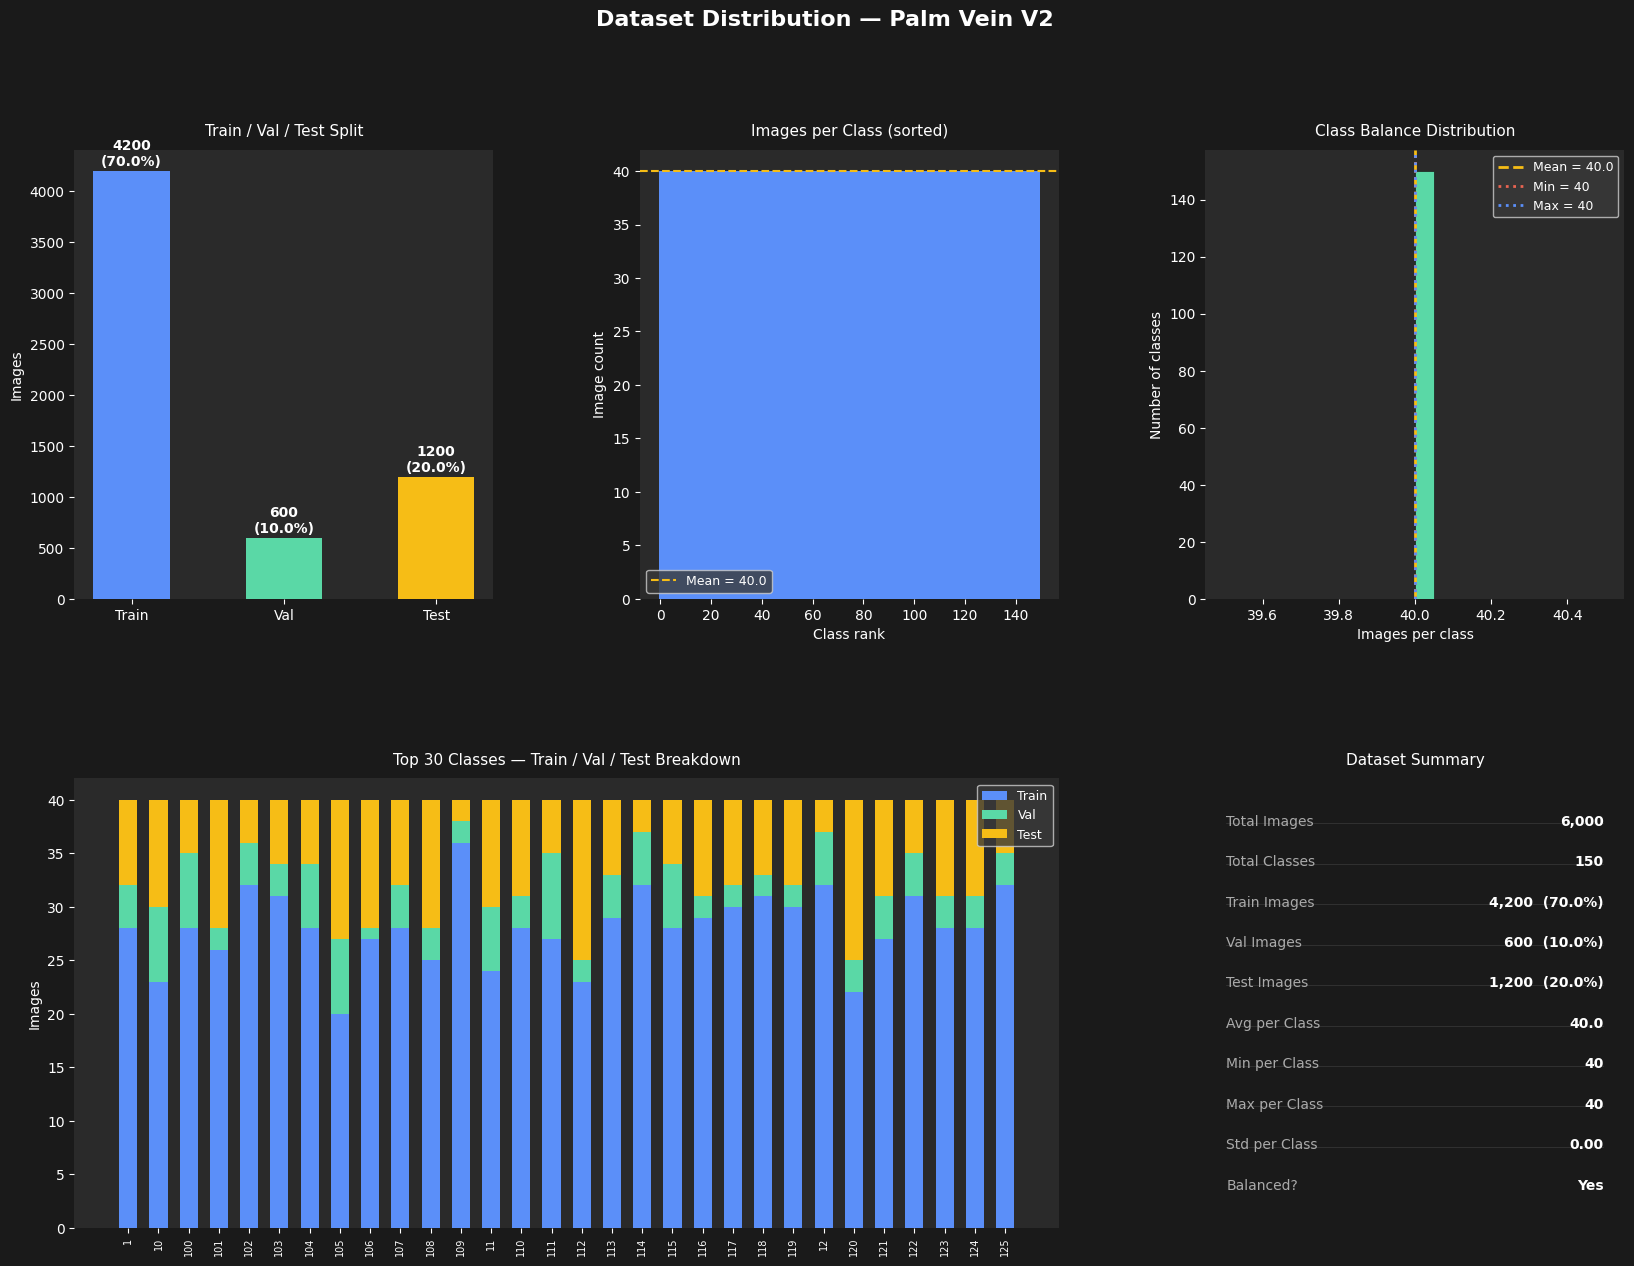

Saved: Outputs/PalmVein_V2/preprocessing/dataset_distribution.png


In [31]:
# ── Hyperparameters ───────────────────────────────────────────────────────────
IMG_SIZE   = 224   # Standard for all models except InceptionV3 (handled per-model)
BATCH_SIZE = 32
NUM_WORKERS = 0    # Set to 0 for Windows compatibility
VAL_SPLIT  = 0.1
TEST_SPLIT = 0.2

# ── ImageNet normalisation stats ──────────────────────────────────────────────
# Used for pretrained models — PVCNN uses its own stats computed from data
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ── Transforms ────────────────────────────────────────────────────────────────
train_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    T.RandomErasing(p=0.1),
])

val_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# ── Custom Dataset ────────────────────────────────────────────────────────────
class PalmVeinDataset(Dataset):
    """
    Loads preprocessed palm vein images from folder structure:
    root/class_name/image.png
    """
    def __init__(self, root, transform=None):
        self.root      = Path(root)
        self.transform = transform
        self.classes   = sorted([d.name for d in self.root.iterdir() if d.is_dir()])
        self.class_to_idx = {c: i for i, c in enumerate(self.classes)}

        self.samples = []
        img_ext = {'.png', '.jpg', '.jpeg', '.bmp'}
        for cls in self.classes:
            cls_dir = self.root / cls
            for img_path in cls_dir.rglob('*'):
                if img_path.suffix.lower() in img_ext:
                    self.samples.append((img_path, self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label


# ── Build datasets ────────────────────────────────────────────────────────────
full_dataset = PalmVeinDataset(PREPROCESSED_PATH)
NUM_CLASSES  = len(full_dataset.classes)
CLASS_NAMES  = full_dataset.classes
print(f'Total images:  {len(full_dataset)}')
print(f'Total classes: {NUM_CLASSES}')
print(f'Sample classes: {CLASS_NAMES[:10]}')

# Deterministic split
total     = len(full_dataset)
n_test    = int(total * TEST_SPLIT)
n_val     = int(total * VAL_SPLIT)
n_train   = total - n_test - n_val

generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds, test_ds = random_split(
    full_dataset, [n_train, n_val, n_test], generator=generator
)

# Apply transforms to each split
train_ds.dataset = PalmVeinDataset(PREPROCESSED_PATH, transform=train_transforms)
val_ds.dataset   = PalmVeinDataset(PREPROCESSED_PATH, transform=val_transforms)
test_ds.dataset  = PalmVeinDataset(PREPROCESSED_PATH, transform=val_transforms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f'\nTrain: {n_train} | Val: {n_val} | Test: {n_test}')
print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}')

# ── Dataset Distribution Charts ───────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from collections import Counter

# Count samples per class in each split
def count_labels(subset):
    labels = [subset.dataset.samples[i][1] for i in subset.indices]
    return Counter(labels)

train_counts = count_labels(train_ds)
val_counts   = count_labels(val_ds)
test_counts  = count_labels(test_ds)

total_per_class = [train_counts.get(i,0) + val_counts.get(i,0) + test_counts.get(i,0)
                   for i in range(NUM_CLASSES)]

# ── Figure ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 14), facecolor='#1a1a1a')
fig.suptitle('Dataset Distribution — Palm Vein V2', fontsize=16,
             fontweight='bold', color='white', y=0.98)

gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

BAR_COLORS = ['#5B8FF9', '#5AD8A6', '#F6BD16', '#E86452']

# ── Plot 1: Total images per split ───────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
splits      = ['Train', 'Val', 'Test']
split_sizes = [n_train, n_val, n_test]
bars = ax1.bar(splits, split_sizes, color=BAR_COLORS[:3], edgecolor='none', width=0.5)
for bar, val in zip(bars, split_sizes):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
             f'{val}\n({val/total*100:.1f}%)', ha='center', va='bottom',
             color='white', fontsize=10, fontweight='bold')
ax1.set_title('Train / Val / Test Split', color='white', fontsize=11, pad=10)
ax1.set_ylabel('Images', color='white')
ax1.tick_params(colors='white')
ax1.set_facecolor('#2a2a2a')
for spine in ax1.spines.values(): spine.set_visible(False)

# ── Plot 2: Images per class (sorted) ────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
sorted_counts = sorted(total_per_class, reverse=True)
ax2.bar(range(NUM_CLASSES), sorted_counts, color='#5B8FF9', edgecolor='none', width=1.0)
ax2.axhline(np.mean(total_per_class), color='#F6BD16', linewidth=1.5,
            linestyle='--', label=f'Mean = {np.mean(total_per_class):.1f}')
ax2.set_title('Images per Class (sorted)', color='white', fontsize=11, pad=10)
ax2.set_xlabel('Class rank', color='white')
ax2.set_ylabel('Image count', color='white')
ax2.tick_params(colors='white')
ax2.set_facecolor('#2a2a2a')
ax2.legend(facecolor='#3a3a3a', labelcolor='white', fontsize=9)
for spine in ax2.spines.values(): spine.set_visible(False)

# ── Plot 3: Class balance histogram ──────────────────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
ax3.hist(total_per_class, bins=20, color='#5AD8A6', edgecolor='#1a1a1a', linewidth=0.5)
ax3.axvline(np.mean(total_per_class), color='#F6BD16', linewidth=2,
            linestyle='--', label=f'Mean = {np.mean(total_per_class):.1f}')
ax3.axvline(np.min(total_per_class),  color='#E86452', linewidth=2,
            linestyle=':',  label=f'Min = {np.min(total_per_class)}')
ax3.axvline(np.max(total_per_class),  color='#5B8FF9', linewidth=2,
            linestyle=':',  label=f'Max = {np.max(total_per_class)}')
ax3.set_title('Class Balance Distribution', color='white', fontsize=11, pad=10)
ax3.set_xlabel('Images per class', color='white')
ax3.set_ylabel('Number of classes', color='white')
ax3.tick_params(colors='white')
ax3.set_facecolor('#2a2a2a')
ax3.legend(facecolor='#3a3a3a', labelcolor='white', fontsize=9)
for spine in ax3.spines.values(): spine.set_visible(False)

# ── Plot 4: Train vs Val vs Test per class (stacked, top 30 classes) ─────────
ax4 = fig.add_subplot(gs[1, :2])
top_n = 30
top_classes = sorted(range(NUM_CLASSES), key=lambda i: total_per_class[i], reverse=True)[:top_n]
top_names   = [CLASS_NAMES[i] for i in top_classes]
tr = [train_counts.get(i,0) for i in top_classes]
vl = [val_counts.get(i,0)   for i in top_classes]
te = [test_counts.get(i,0)  for i in top_classes]
x  = np.arange(top_n)
w  = 0.6
ax4.bar(x, tr, w, label='Train', color='#5B8FF9')
ax4.bar(x, vl, w, bottom=tr,                    label='Val',   color='#5AD8A6')
ax4.bar(x, te, w, bottom=[t+v for t,v in zip(tr,vl)], label='Test', color='#F6BD16')
ax4.set_xticks(x)
ax4.set_xticklabels(top_names, rotation=90, fontsize=7, color='white')
ax4.set_title(f'Top {top_n} Classes — Train / Val / Test Breakdown', color='white', fontsize=11, pad=10)
ax4.set_ylabel('Images', color='white')
ax4.tick_params(colors='white')
ax4.set_facecolor('#2a2a2a')
ax4.legend(facecolor='#3a3a3a', labelcolor='white', fontsize=9)
for spine in ax4.spines.values(): spine.set_visible(False)

# ── Plot 5: Summary stats box ─────────────────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 2])
ax5.set_facecolor('#2a2a2a')
ax5.axis('off')
for spine in ax5.spines.values(): spine.set_visible(False)

stats = [
    ('Total Images',    f'{total:,}'),
    ('Total Classes',   f'{NUM_CLASSES}'),
    ('Train Images',    f'{n_train:,}  ({n_train/total*100:.1f}%)'),
    ('Val Images',      f'{n_val:,}  ({n_val/total*100:.1f}%)'),
    ('Test Images',     f'{n_test:,}  ({n_test/total*100:.1f}%)'),
    ('Avg per Class',   f'{np.mean(total_per_class):.1f}'),
    ('Min per Class',   f'{np.min(total_per_class)}'),
    ('Max per Class',   f'{np.max(total_per_class)}'),
    ('Std per Class',   f'{np.std(total_per_class):.2f}'),
    ('Balanced?',       'Yes' if np.std(total_per_class) < 5 else 'No'),
]

ax5.set_title('Dataset Summary', color='white', fontsize=11, pad=10)
for idx, (label, value) in enumerate(stats):
    y_pos = 0.92 - idx * 0.09
    ax5.text(0.05, y_pos, label,  transform=ax5.transAxes,
             color='#aaaaaa', fontsize=10, va='top')
    ax5.text(0.95, y_pos, value,  transform=ax5.transAxes,
             color='white',   fontsize=10, va='top', ha='right', fontweight='bold')
    if idx < len(stats)-1:
        ax5.plot([0.05, 0.95], [y_pos - 0.02, y_pos - 0.02],
                 color='#3a3a3a', linewidth=0.5, transform=ax5.transAxes)

plt.savefig(f'{OUTPUT_BASE}/preprocessing/dataset_distribution.png',
            dpi=150, bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f'Saved: {OUTPUT_BASE}/preprocessing/dataset_distribution.png')

## Cell 5 · Training & Evaluation Utilities

Shared functions used by every model training cell:

- `train_one_epoch` — one full pass through training set with mixed precision
- `evaluate` — validation/test accuracy and loss
- `train_model` — full training loop with early stopping, LR scheduling, checkpointing
- `plot_history` — saves training curves
- `is_trained` — checks if a model checkpoint already exists (skip-if-trained logic)

### Key training strategies

| Strategy | Detail |
|----------|--------|
| **Mixed Precision (AMP)** | float16 on GPU — ~2× faster, half VRAM |
| **OneCycleLR** | Warm-up + cosine decay — fastest convergence |
| **Early Stopping** | patience=7, restores best weights |
| **Label Smoothing** | 0.1 — improves generalisation to unseen data |
| **Gradient Clipping** | max_norm=1.0 — prevents exploding gradients |

In [33]:
from torch.amp import GradScaler, autocast
import copy

def is_trained(model_name):
    """Check if model checkpoint exists — skip training if already done."""
    path = f'{MODELS_DIR}/{model_name}_best.pth'
    exists = os.path.exists(path)
    if exists:
        print(f'  ✓ {model_name} already trained — loading from {path}')
    return exists


def train_one_epoch(model, loader, criterion, optimizer, scaler, epoch, num_epochs):
    """One training epoch with mixed precision and live progress bar."""
    tqdm._instances.clear()
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    pbar = tqdm(loader, desc=f'  Epoch {epoch:02d}/{num_epochs} [Train]',
                leave=False, ncols=100, colour='blue')

    for imgs, labels in pbar:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()

        with autocast('cuda'):
            outputs = model(imgs)
            loss    = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * imgs.size(0)
        preds       = outputs.argmax(dim=1)
        correct    += (preds == labels).sum().item()
        total      += imgs.size(0)

        pbar.set_postfix({
            'loss': f'{total_loss/total:.4f}',
            'acc':  f'{correct/total*100:.2f}%'
        })

    return total_loss / total, correct / total


def evaluate(model, loader, epoch, num_epochs):
    """Evaluate with live progress bar."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    criterion = nn.CrossEntropyLoss()

    pbar = tqdm(loader, desc=f'  Epoch {epoch:02d}/{num_epochs} [Val]  ',
                leave=False, ncols=100, colour='green')

    with torch.no_grad():
        for imgs, labels in pbar:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            with autocast('cuda'):
                outputs = model(imgs)
                loss    = criterion(outputs, labels)
            total_loss += loss.item() * imgs.size(0)
            correct    += (outputs.argmax(1) == labels).sum().item()
            total      += imgs.size(0)

            pbar.set_postfix({
                'loss': f'{total_loss/total:.4f}',
                'acc':  f'{correct/total*100:.2f}%'
            })

    return total_loss / total, correct / total


def train_model(model, model_name, num_epochs=30, lr=1e-4):
    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=lr,
        steps_per_epoch=len(train_loader),
        epochs=num_epochs,
        pct_start=0.1,
        anneal_strategy='cos'
    )

    scaler    = GradScaler('cuda')
    history   = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
    best_val_acc = 0.0
    best_weights = None
    patience_cnt = 0
    PATIENCE     = 7
    save_path    = f'{MODELS_DIR}/{model_name}_best.pth'
    resume_path  = f'{MODELS_DIR}/{model_name}_checkpoint.pth'
    start_epoch  = 1

    # ── Resume from interrupted training ──────────────────────────────────────
    if os.path.exists(resume_path):
        print(f'  Resuming {model_name} from checkpoint...')
        ckpt = torch.load(resume_path, map_location=DEVICE)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        scheduler.load_state_dict(ckpt['scheduler_state'])
        scaler.load_state_dict(ckpt['scaler_state'])
        history      = ckpt['history']
        best_val_acc = ckpt['best_val_acc']
        patience_cnt = ckpt['patience_cnt']
        start_epoch  = ckpt['epoch'] + 1
        best_weights = ckpt['best_weights']
        print(f'  Resumed from epoch {start_epoch-1} | Best val acc so far: {best_val_acc*100:.2f}%')
    else:
        print(f'  Starting {model_name} from scratch')

    print(f'\n\033[34mTraining {model_name}...\033[0m')
    print(f'{"─"*70}')
    start = time.time()

    for epoch in range(start_epoch, num_epochs + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, epoch, num_epochs)
        val_loss, val_acc = evaluate(model, val_loader, epoch, num_epochs)
        scheduler.step()

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        improved = val_acc > best_val_acc
        if improved:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, save_path)
            patience_cnt = 0
            flag = '\033[32m✓ saved\033[0m'
        else:
            patience_cnt += 1
            flag = f'\033[33mpatience {patience_cnt}/{PATIENCE}\033[0m'

        # Save full checkpoint after every epoch for resume capability
        torch.save({
            'epoch':           epoch,
            'model_state':     model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'scheduler_state': scheduler.state_dict(),
            'scaler_state':    scaler.state_dict(),
            'history':         history,
            'best_val_acc':    best_val_acc,
            'patience_cnt':    patience_cnt,
            'best_weights':    best_weights,
        }, resume_path)

        elapsed  = time.time() - start
        avg_time = elapsed / (epoch - start_epoch + 1)
        eta_secs = avg_time * (num_epochs - epoch)
        eta_str  = f'{int(eta_secs//60)}m {int(eta_secs%60)}s'

        print(f'  Epoch {epoch:02d}/{num_epochs} | '
              f'Train {train_acc*100:.2f}% loss {train_loss:.4f} | '
              f'Val {val_acc*100:.2f}% loss {val_loss:.4f} | '
              f'Best {best_val_acc*100:.2f}% | '
              f'LR {scheduler.get_last_lr()[0]:.2e} | '
              f'ETA {eta_str} | {flag}')

        if patience_cnt >= PATIENCE:
            print(f'\033[33m  Early stopping at epoch {epoch}\033[0m')
            break

    # Clean up checkpoint after successful completion
    if os.path.exists(resume_path):
        os.remove(resume_path)

    model.load_state_dict(best_weights)
    elapsed = time.time() - start
    print(f'{"─"*70}')
    print(f'\033[34mFinished {model_name} in {elapsed/60:.1f} min | Best val acc: {best_val_acc*100:.2f}%\033[0m')

    with open(f'{MODELS_DIR}/{model_name}_history.json', 'w') as f:
        json.dump(history, f)

    return model, history


def plot_history(history, model_name):
    """Plot and save training curves."""
    epochs = range(1, len(history['train_acc']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    axes[0].plot(epochs, [a*100 for a in history['train_acc']], label='Train')
    axes[0].plot(epochs, [a*100 for a in history['val_acc']],   label='Val')
    axes[0].set_title(f'{model_name} — Accuracy')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy (%)')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, history['train_loss'], label='Train')
    axes[1].plot(epochs, history['val_loss'],   label='Val')
    axes[1].set_title(f'{model_name} — Loss')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.suptitle(f'{model_name} Training History', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_BASE}/curves/{model_name}_curves.png', dpi=150, bbox_inches='tight')
    plt.show()


def load_model(model, model_name):
    """Load saved best weights into model."""
    path = f'{MODELS_DIR}/{model_name}_best.pth'
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    model = model.to(DEVICE)
    model.eval()
    return model


print('Training utilities ready.')

Training utilities ready.


In [34]:
import gc
gc.collect()
torch.cuda.empty_cache()
print(f'Free VRAM: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB')

Free VRAM: 9.6 GB


## Model · EfficientNetV2-S

State-of-the-art efficiency — strong on fine-grained texture features. Compound scaling of depth/width/resolution.

> **Skip-if-trained:** If `EfficientNetV2_S_best.pth` exists this cell loads weights and skips training.

  ✓ EfficientNetV2_S already trained — loading from Saved Models/PalmVein_V2/EfficientNetV2_S_best.pth


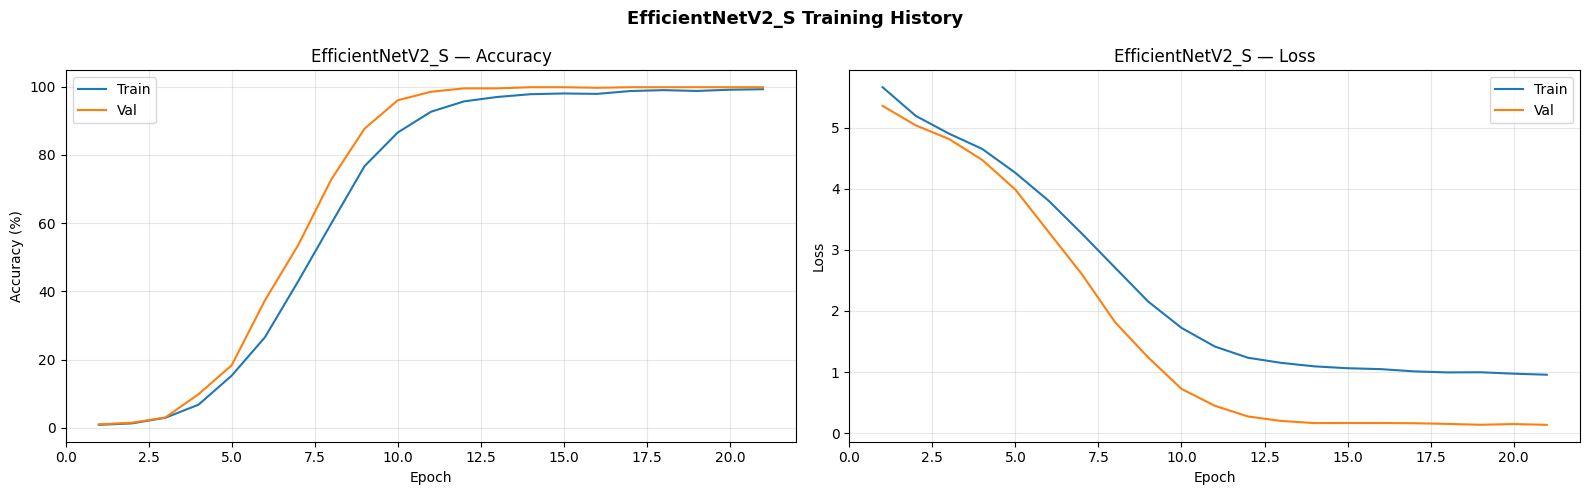

EfficientNetV2_S ready. Total models: 11

  ── EfficientNetV2_S Results ──
  Best Val Accuracy : 99.83%
  Best Epoch        : 14/21
  Final Train Acc   : 99.24%


In [35]:
MODEL_NAME = 'EfficientNetV2_S'

# ── Build model ──────────────────────────────────────────────────────────────
model = timm.create_model('tf_efficientnetv2_s', pretrained=True, num_classes=NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
    if os.path.exists(history_path):
        with open(history_path) as f:
            history = json.load(f)
        plot_history(history, MODEL_NAME)
    else:
        print(f'  No history file — model loaded, curves unavailable')
        history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')

## Model · ResNet50

Classic deep residual network. Excellent baseline, strong generalisation via skip connections.

> **Skip-if-trained:** If `ResNet50_best.pth` exists this cell loads weights and skips training.

  ✓ ResNet50 already trained — loading from Saved Models/PalmVein_V2/ResNet50_best.pth


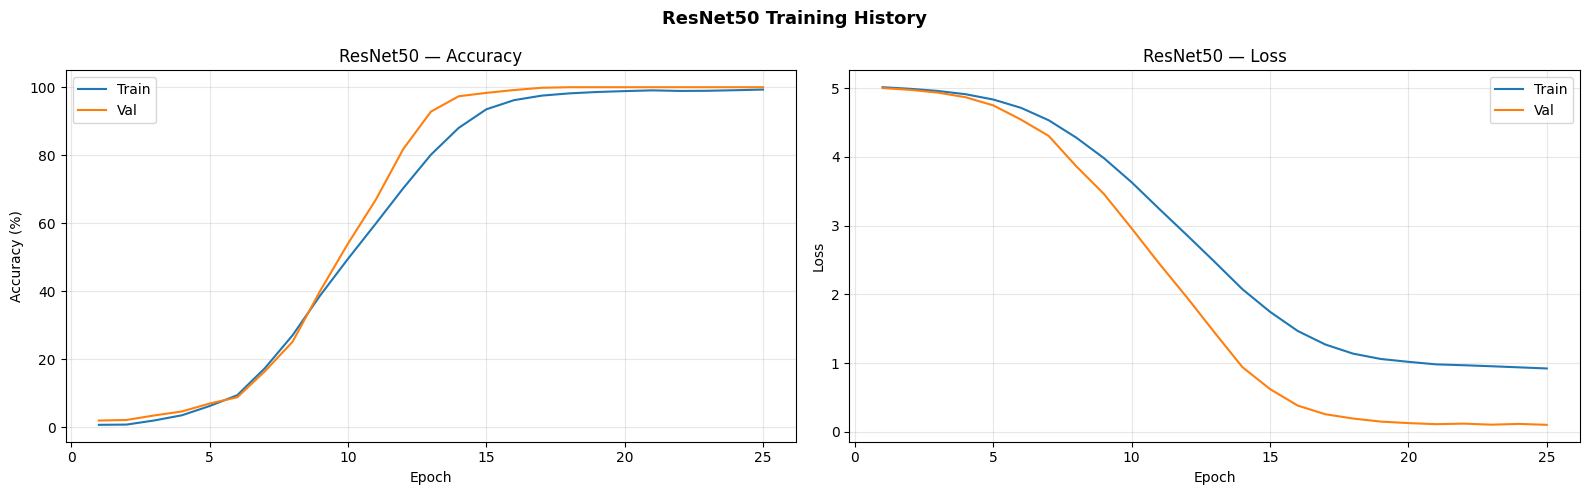

ResNet50 ready. Total models: 11

  ── ResNet50 Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 18/25
  Final Train Acc   : 99.31%


In [36]:
MODEL_NAME = 'ResNet50'

# ── Build model ──────────────────────────────────────────────────────────────
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')


## Model · ResNet101

Deeper ResNet — more representational capacity for complex inter-class vein patterns.

> **Skip-if-trained:** If `ResNet101_best.pth` exists this cell loads weights and skips training.

  ✓ ResNet101 already trained — loading from Saved Models/PalmVein_V2/ResNet101_best.pth


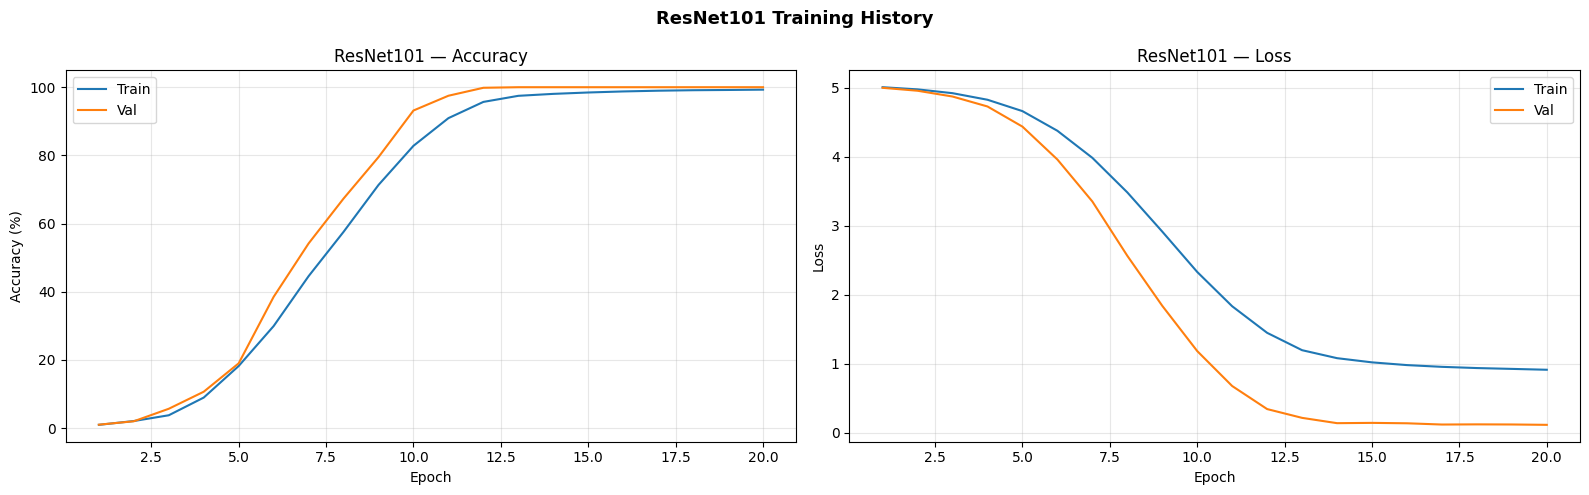

ResNet101 ready. Total models: 11

  ── ResNet101 Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 13/20
  Final Train Acc   : 99.29%


In [37]:
MODEL_NAME = 'ResNet101'

# ── Build model ──────────────────────────────────────────────────────────────
model = models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')


## Model · DenseNet121

Dense connections — every layer connects to all subsequent layers. Excellent feature reuse for texture biometrics.

> **Skip-if-trained:** If `DenseNet121_best.pth` exists this cell loads weights and skips training.

  ✓ DenseNet121 already trained — loading from Saved Models/PalmVein_V2/DenseNet121_best.pth


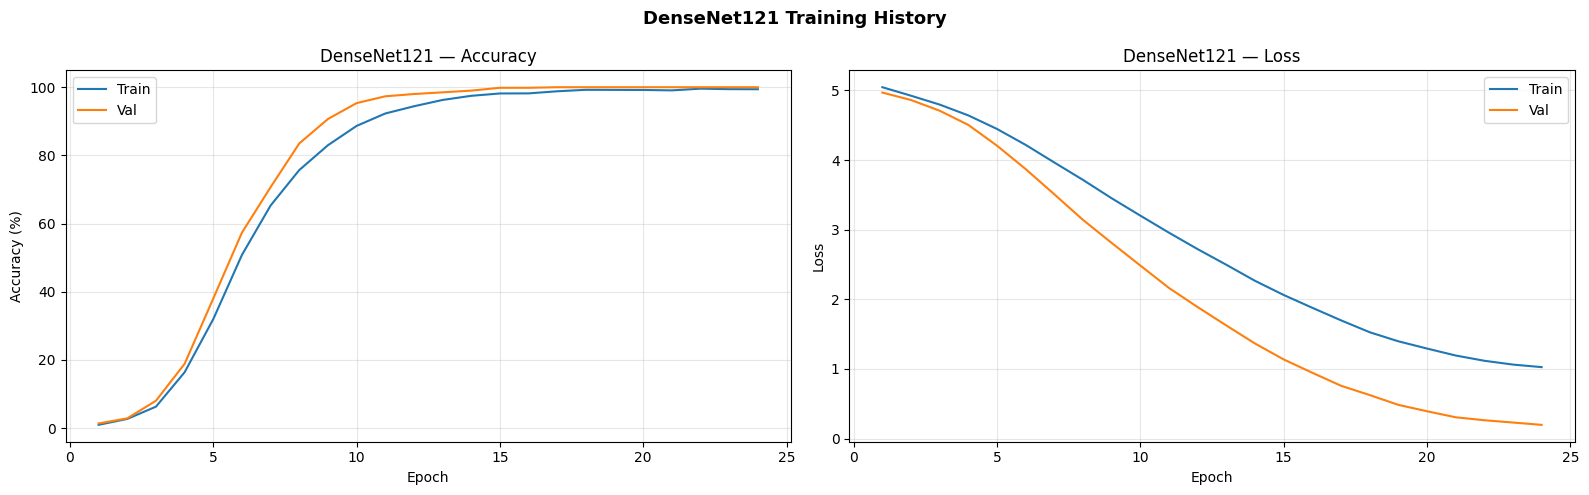

DenseNet121 ready. Total models: 11

  ── DenseNet121 Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 17/24
  Final Train Acc   : 99.40%


In [38]:
MODEL_NAME = 'DenseNet121'

# ── Build model ──────────────────────────────────────────────────────────────
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = nn.Linear(model.classifier.in_features, NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')


## Model · MobileNetV3-Large

Lightweight architecture with SE attention. Fast inference — good for deployment scenarios.

> **Skip-if-trained:** If `MobileNetV3_Large_best.pth` exists this cell loads weights and skips training.

  ✓ MobileNetV3_Large already trained — loading from Saved Models/PalmVein_V2/MobileNetV3_Large_best.pth


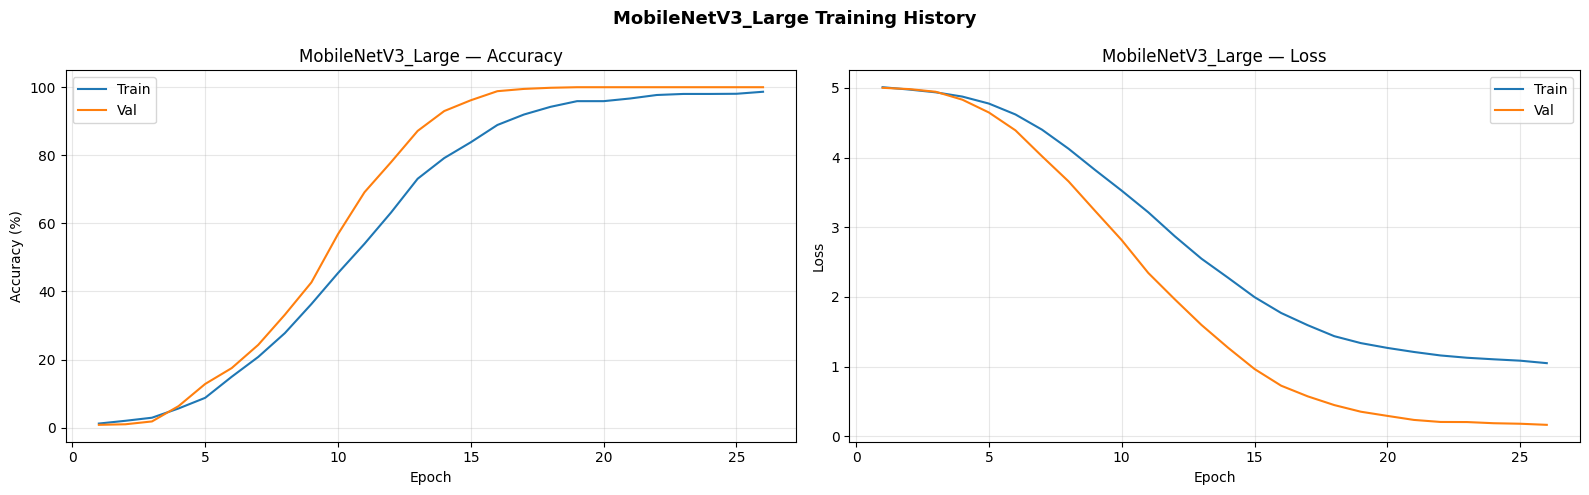

MobileNetV3_Large ready. Total models: 11

  ── MobileNetV3_Large Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 19/26
  Final Train Acc   : 98.67%


In [39]:
MODEL_NAME = 'MobileNetV3_Large'

# ── Build model ──────────────────────────────────────────────────────────────
model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')


## Model · VGG16

Continuity with V1 — allows direct comparison. Deep conv stack captures hierarchical vein features.

> **Skip-if-trained:** If `VGG16_best.pth` exists this cell loads weights and skips training.

  ✓ VGG16 already trained — loading from Saved Models/PalmVein_V2/VGG16_best.pth


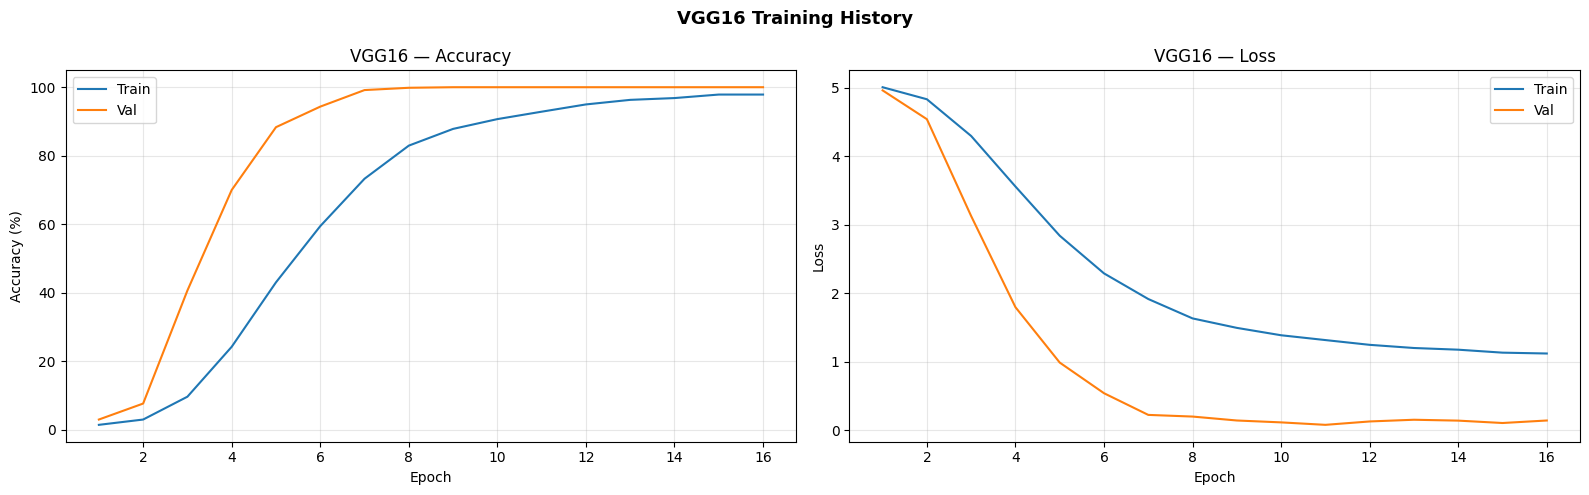

VGG16 ready. Total models: 11

  ── VGG16 Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 9/16
  Final Train Acc   : 97.86%


In [40]:
MODEL_NAME = 'VGG16'

# ── Build model ──────────────────────────────────────────────────────────────
model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
model.classifier[-1] = nn.Linear(4096, NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')


## Model · VGG19

Deeper VGG — 4 extra conv layers vs VGG16. More capacity for fine vein detail.

> **Skip-if-trained:** If `VGG19_best.pth` exists this cell loads weights and skips training.

  ✓ VGG19 already trained — loading from Saved Models/PalmVein_V2/VGG19_best.pth


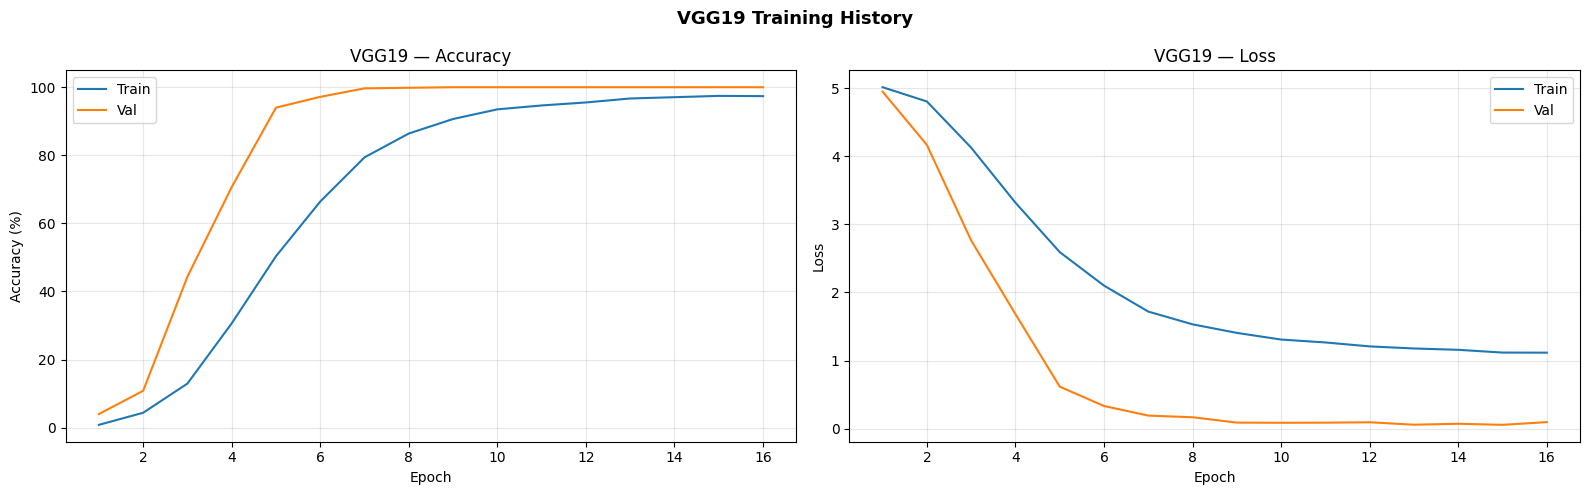

VGG19 ready. Total models: 11

  ── VGG19 Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 9/16
  Final Train Acc   : 97.38%


In [41]:
MODEL_NAME = 'VGG19'

# ── Build model ──────────────────────────────────────────────────────────────
model = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1)
model.classifier[-1] = nn.Linear(4096, NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')


## Model · InceptionV3

Multi-scale parallel convolutions — captures vein patterns at different spatial scales simultaneously.

> **Skip-if-trained:** If `InceptionV3_best.pth` exists this cell loads weights and skips training.

  ✓ InceptionV3 already trained — loading from Saved Models/PalmVein_V2/InceptionV3_best.pth


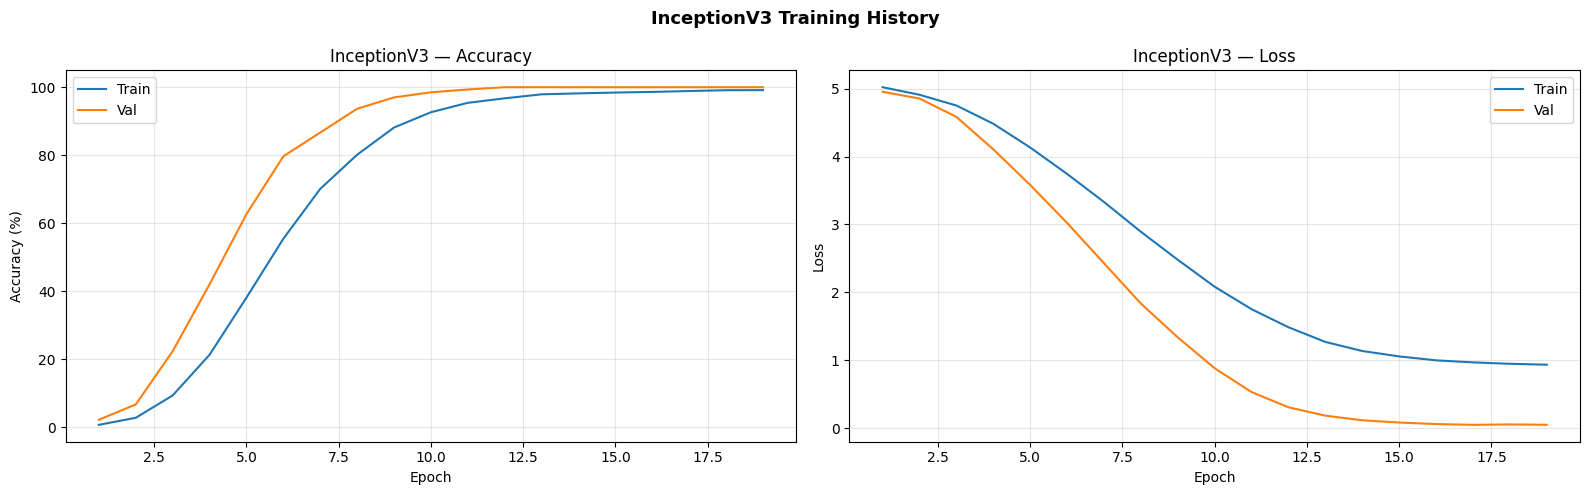

InceptionV3 ready. Total models: 11

  ── InceptionV3 Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 12/19
  Final Train Acc   : 99.14%


In [42]:
MODEL_NAME = 'InceptionV3'

import gc
gc.collect()
torch.cuda.empty_cache()

# 299×299 loaders
inc_train_ds = torch.utils.data.Subset(
    PalmVeinDataset(PREPROCESSED_PATH, transform=T.Compose([
        T.Resize((299,299)), T.RandomHorizontalFlip(p=0.5),
        T.RandomRotation(15), T.ColorJitter(brightness=0.2, contrast=0.2),
        T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        T.RandomErasing(p=0.1),
    ])), train_ds.indices)
inc_val_ds = torch.utils.data.Subset(
    PalmVeinDataset(PREPROCESSED_PATH, transform=T.Compose([
        T.Resize((299,299)), T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])), val_ds.indices)

train_loader = DataLoader(inc_train_ds, batch_size=16, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(inc_val_ds,   batch_size=16, shuffle=False, num_workers=0, pin_memory=True)

# Build model
model = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
model.aux_logits = False
model.AuxLogits  = None
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

# ── Skip training if already done ─────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
    if os.path.exists(history_path):
        with open(history_path) as f:
            history = json.load(f)
        plot_history(history, MODEL_NAME)
    else:
        print('  No history file — model loaded, curves unavailable')
        history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Restore standard loaders
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

trained_models[MODEL_NAME] = model
print(f'InceptionV3 ready. Total models: {len(trained_models)}')

# ── Display results ───────────────────────────────────────────────────────────
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')

## Model · RegNetY-8GF

Designed via neural architecture search — optimal depth/width ratio. Strong generalisation on unseen domains.

> **Skip-if-trained:** If `RegNetY_8GF_best.pth` exists this cell loads weights and skips training.

  ✓ RegNetY_8GF already trained — loading from Saved Models/PalmVein_V2/RegNetY_8GF_best.pth


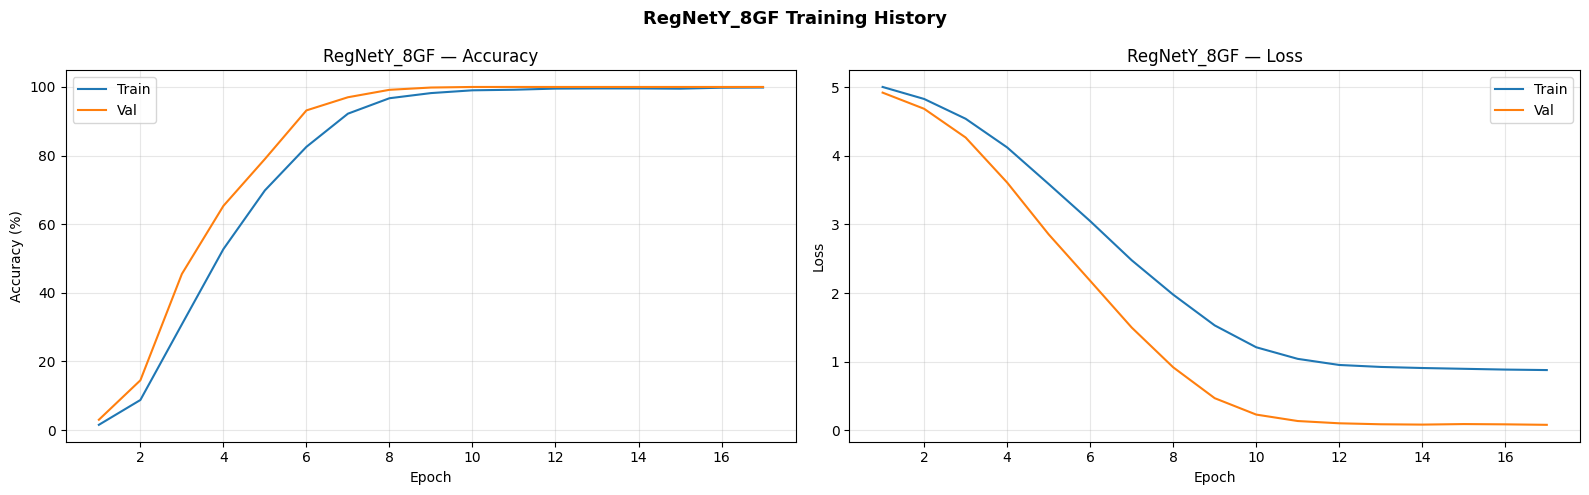

RegNetY_8GF ready. Total models: 11

  ── RegNetY_8GF Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 10/17
  Final Train Acc   : 99.83%


In [43]:
MODEL_NAME = 'RegNetY_8GF'

# ── Build model ──────────────────────────────────────────────────────────────
model = models.regnet_y_8gf(weights=models.RegNet_Y_8GF_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')

## Model · ConvNeXt-Tiny

Modern CNN — matches Vision Transformer performance. Best out-of-domain generalisation of all CNN families.

> **Skip-if-trained:** If `ConvNeXt_Tiny_best.pth` exists this cell loads weights and skips training.

  ✓ ConvNeXt_Tiny already trained — loading from Saved Models/PalmVein_V2/ConvNeXt_Tiny_best.pth


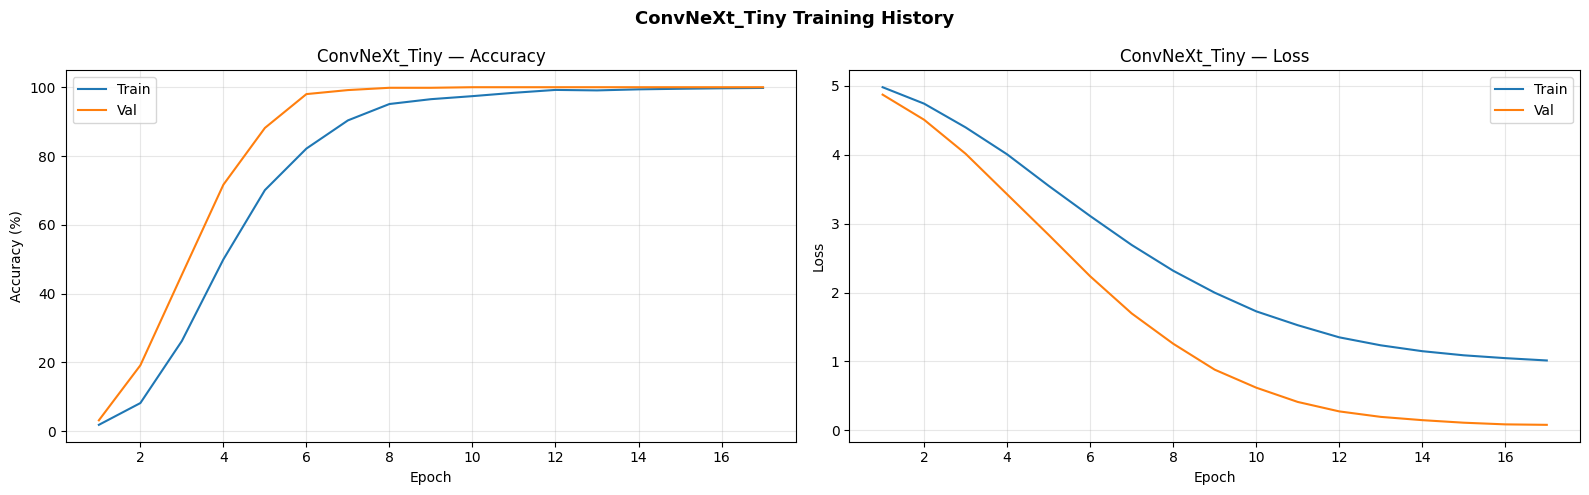

ConvNeXt_Tiny ready. Total models: 11

  ── ConvNeXt_Tiny Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 10/17
  Final Train Acc   : 99.79%


In [44]:
MODEL_NAME = 'ConvNeXt_Tiny'

# ── Build model ──────────────────────────────────────────────────────────────
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)

# ── Train or load ─────────────────────────────────────────────────────────────
if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    model, history = train_model(model, MODEL_NAME, num_epochs=30, lr=3e-4)
    plot_history(history, MODEL_NAME)

# Store for ensemble
if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'{MODEL_NAME} ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')


## Model · Custom PVCNN (Palm Vein CNN)

A CNN designed specifically for near-infrared palm vein images.

### Design decisions

| Component | Choice | Reason |
|-----------|--------|--------|
| **Depthwise separable convs** | MobileNet-style | Efficient, good for texture patterns |
| **SE Attention** | Squeeze-and-Excitation | Focuses on vein-relevant channels |
| **Multi-scale blocks** | 3×3 + 5×5 parallel | Captures fine veins + major branches |
| **GELU activation** | Instead of ReLU | Smoother gradients, better convergence |
| **Batch Norm** | After every conv | Stabilises training, acts as regulariser |

> **Skip-if-trained:** If `PVCNN_best.pth` exists this cell loads weights and skips training.

PVCNN parameters: 3,696,434
  ✓ PVCNN already trained — loading from Saved Models/PalmVein_V2/PVCNN_best.pth


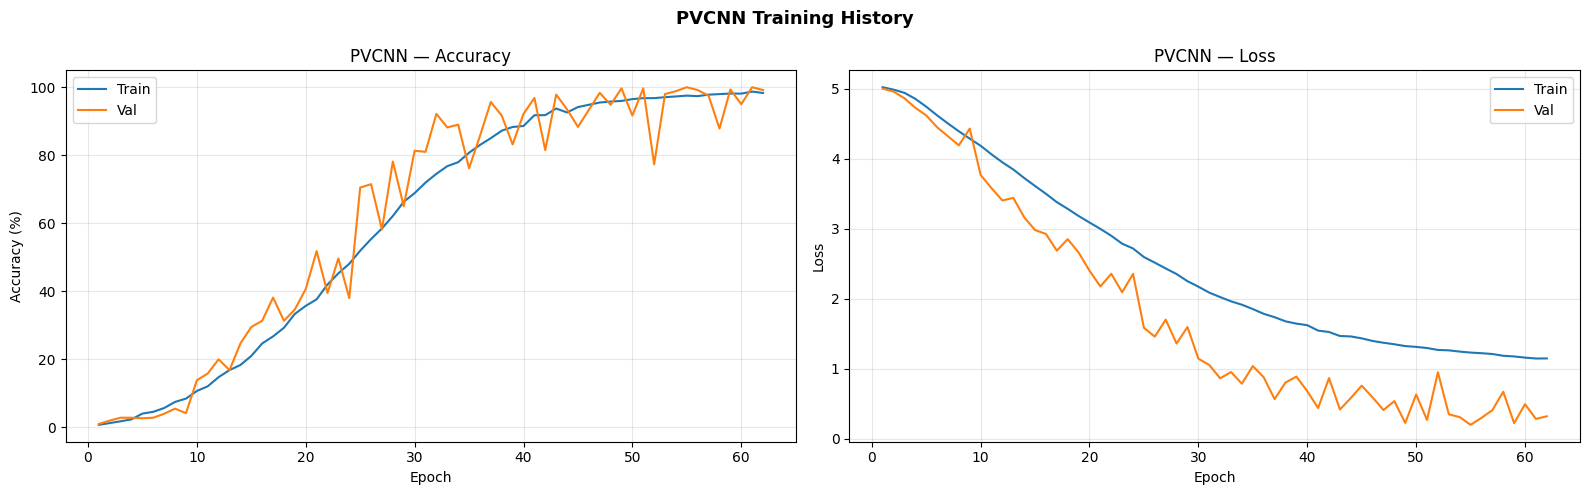

PVCNN ready. Total models: 11

  ── PVCNN Results ──
  Best Val Accuracy : 100.00%
  Best Epoch        : 55/62
  Final Train Acc   : 98.31%


In [45]:
class SEBlock(nn.Module):
    """Squeeze-and-Excitation attention — focuses on informative channels."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels, channels // reduction),
            nn.GELU(),
            nn.Linear(channels // reduction, channels),
            nn.Sigmoid()
        )
    def forward(self, x):
        w = self.se(x).unsqueeze(-1).unsqueeze(-1)
        return x * w


class MultiScaleBlock(nn.Module):
    """Parallel 3x3 and 5x5 convolutions — captures vein patterns at multiple scales."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        mid = out_ch // 2
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_ch, mid, 3, padding=1, bias=False),
            nn.BatchNorm2d(mid), nn.GELU()
        )
        self.branch5 = nn.Sequential(
            nn.Conv2d(in_ch, mid, 5, padding=2, bias=False),
            nn.BatchNorm2d(mid), nn.GELU()
        )
        self.se = SEBlock(out_ch)
        self.proj = nn.Sequential(
            nn.Conv2d(out_ch, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch), nn.GELU()
        )

    def forward(self, x):
        x = torch.cat([self.branch3(x), self.branch5(x)], dim=1)
        x = self.se(x)
        return self.proj(x)


class PVCNN(nn.Module):
    """
    Palm Vein CNN — custom architecture for near-infrared biometric images.
    Multi-scale feature extraction + SE attention + depthwise separable convolutions.
    """
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.GELU()
        )
        self.stage1 = nn.Sequential(MultiScaleBlock(32, 64),  nn.MaxPool2d(2))
        self.stage2 = nn.Sequential(MultiScaleBlock(64, 128), nn.MaxPool2d(2))
        self.stage3 = nn.Sequential(MultiScaleBlock(128, 256), nn.MaxPool2d(2))
        self.stage4 = nn.Sequential(MultiScaleBlock(256, 512), nn.MaxPool2d(2))
        self.pool   = nn.AdaptiveAvgPool2d(1)
        self.head   = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 512), nn.GELU(), nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.pool(x)
        return self.head(x)


MODEL_NAME = 'PVCNN'
model = PVCNN(num_classes=NUM_CLASSES)
print(f'PVCNN parameters: {sum(p.numel() for p in model.parameters()):,}')

if is_trained(MODEL_NAME):
    model = load_model(model, MODEL_NAME)
    with open(f'{MODELS_DIR}/{MODEL_NAME}_history.json') as f:
        history = json.load(f)
    plot_history(history, MODEL_NAME)
else:
    # Custom model trains from scratch — lower initial LR
    model, history = train_model(model, MODEL_NAME, num_epochs=70, lr=1e-3)
    plot_history(history, MODEL_NAME)

if 'trained_models' not in dir(): trained_models = {}
trained_models[MODEL_NAME] = model
print(f'PVCNN ready. Total models: {len(trained_models)}')

# ── Display best results for this model ──────────────────────────────────────
# Shows best validation accuracy, epoch it was achieved, and training curves
# Runs whether model was just trained or loaded from a previous checkpoint
history_path = f'{MODELS_DIR}/{MODEL_NAME}_history.json'
if os.path.exists(history_path):
    with open(history_path) as f:
        history = json.load(f)
    best_val   = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    total_eps  = len(history['val_acc'])
    print(f'\n  ── {MODEL_NAME} Results ──')
    print(f'  Best Val Accuracy : {best_val:.2f}%')
    print(f'  Best Epoch        : {best_epoch}/{total_eps}')
    print(f'  Final Train Acc   : {history["train_acc"][-1]*100:.2f}%')
else:
    print(f'  No history file found for {MODEL_NAME}')


## Cell · Load All Trained Models

Run this cell to reload all saved models from disk — useful when starting a new session after training is complete.

In [47]:
import timm

trained_models = {}

# ── Model registry (load all models from disk) ───────────────────────────────
# No special-case skipping by default; InceptionV3 gets special loading logic below
SKIP_FROM_DISK = set()

def build_mobilenet():
    m = models.mobilenet_v3_large()
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, NUM_CLASSES)
    return m

def build_vgg16():
    m = models.vgg16()
    m.classifier[6] = nn.Linear(4096, NUM_CLASSES)
    return m

def build_vgg19():
    m = models.vgg19()
    m.classifier[6] = nn.Linear(4096, NUM_CLASSES)
    return m

def build_convnext():
    m = models.convnext_tiny()
    m.classifier[2] = nn.Linear(m.classifier[2].in_features, NUM_CLASSES)
    return m

def build_inception(aux_logits=False):
    # Use torchvision's inception builder and control aux_logits explicitly
    m = models.inception_v3(aux_logits=aux_logits, transform_input=False)
    if not aux_logits and getattr(m, 'AuxLogits', None) is not None:
        m.aux_logits = False
        m.AuxLogits = None
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    return m

def build_resnet50():
    m = models.resnet50()
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    return m

def build_resnet101():
    m = models.resnet101()
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    return m

def build_densenet():
    m = models.densenet121()
    m.classifier = nn.Linear(m.classifier.in_features, NUM_CLASSES)
    return m

def build_regnet():
    m = models.regnet_y_8gf()
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    return m

model_registry = {
    'EfficientNetV2_S':  lambda: timm.create_model('tf_efficientnetv2_s', pretrained=False, num_classes=NUM_CLASSES),
    'ResNet50':          build_resnet50,
    'ResNet101':         build_resnet101,
    'DenseNet121':       build_densenet,
    'MobileNetV3_Large': build_mobilenet,
    'VGG16':             build_vgg16,
    'VGG19':             build_vgg19,
    'InceptionV3':       lambda: build_inception(aux_logits=False),
    'RegNetY_8GF':       build_regnet,
    'ConvNeXt_Tiny':     build_convnext,
    'PVCNN':             lambda: PVCNN(num_classes=NUM_CLASSES),
}


def _extract_state_dict(raw):
    # Accept either raw state_dict or common checkpoint dict wrappers
    if isinstance(raw, dict):
        if 'state_dict' in raw:
            sd = raw['state_dict']
        elif 'model_state_dict' in raw:
            sd = raw['model_state_dict']
        else:
            sd = raw
    else:
        sd = raw
    # Strip 'module.' prefix if present (from DataParallel/DistributedDataParallel)
    new_sd = {}
    for k, v in sd.items():
        nk = k[7:] if k.startswith('module.') else k
        new_sd[nk] = v
    return new_sd

for name, builder in model_registry.items():
    if name in SKIP_FROM_DISK:
        print(f'  Skipped: {name} — special handling requested')
        continue
    ckpt = f'{MODELS_DIR}/{name}_best.pth'
    if not os.path.exists(ckpt):
        print(f'  Missing: {name} — run its training cell first')
        continue

    # Load checkpoint and try a few resilient strategies for InceptionV3
    raw = torch.load(ckpt, map_location=DEVICE)
    sd = _extract_state_dict(raw)

    if name == 'InceptionV3':
        # Try loading into standard builder (aux_logits=False) first with strict=True
        tried = False
        for aux in (False, True):
            m = build_inception(aux_logits=aux)
            try:
                m.load_state_dict(sd, strict=True)
                tried = True
                break
            except Exception as e:
                # If strict load fails, try non-strict load to accept slight mismatches
                try:
                    m.load_state_dict(sd, strict=False)
                    tried = True
                    print(f'  Loaded (non-strict) {name} with aux_logits={aux} — {e}')
                    break
                except Exception:
                    # continue to next aux setting
                    pass
        if not tried:
            # As a last resort try timm's Inception if available
            try:
                m = timm.create_model('inception_v3', pretrained=False, num_classes=NUM_CLASSES)
                m.load_state_dict(sd, strict=False)
                print(f'  Loaded (timm, non-strict): {name}')
            except Exception as e:
                print(f'  Failed to load InceptionV3: {e}')
                continue
    else:
        m = builder()
        try:
            m.load_state_dict(sd, strict=True)
        except Exception as e:
            try:
                m.load_state_dict(sd, strict=False)
                print(f'  Loaded (non-strict) {name} — {e}')
            except Exception as e2:
                print(f'  Failed to load {name}: {e2}')
                continue

    m = m.to(DEVICE)
    m.eval()
    trained_models[name] = m
    print(f'  Loaded: {name}')

print(f'\nTotal models loaded: {len(trained_models)}')
print('All available models were attempted to load from disk')


  Loaded: EfficientNetV2_S
  Loaded: ResNet50
  Loaded: ResNet101
  Loaded: DenseNet121
  Loaded: MobileNetV3_Large
  Loaded: VGG16
  Loaded: VGG19
  Loaded: InceptionV3
  Loaded: RegNetY_8GF
  Loaded: ConvNeXt_Tiny
  Loaded: PVCNN

Total models loaded: 11
All available models were attempted to load from disk


## Cell · Validation — Standard vs TTA

**Test-Time Augmentation (TTA)** runs multiple augmented versions of each test image through the model and averages the predictions.  
This reduces variance and consistently improves accuracy — especially useful for generalisation to unseen datasets.

### TTA strategy

| Augmentation | Variants | Effect |
|-------------|---------|--------|
| Original | 1 | Baseline |
| Horizontal Flip | 1 | Mirror hand orientation |
| Rotation ±10° | 2 | Camera angle variation |
| Brightness ±0.1 | 2 | Lighting variation |
| **Total passes** | **6** | Averaged → more robust prediction |

In [48]:
import gc
gc.collect()
torch.cuda.empty_cache()
print(f'Free VRAM: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB')

Free VRAM: 9.5 GB


Cell A — First 7 models:

In [49]:
# Check which models are loaded and which are missing
print('Loaded models:')
for name in model_registry.keys():
    status = '✓ loaded' if name in trained_models else '✗ missing'
    ckpt   = f'{MODELS_DIR}/{name}_best.pth'
    exists = '(pth exists)' if os.path.exists(ckpt) else '(NO pth file)'
    print(f'  {name:20s} | {status} | {exists}')

Loaded models:
  EfficientNetV2_S     | ✓ loaded | (pth exists)
  ResNet50             | ✓ loaded | (pth exists)
  ResNet101            | ✓ loaded | (pth exists)
  DenseNet121          | ✓ loaded | (pth exists)
  MobileNetV3_Large    | ✓ loaded | (pth exists)
  VGG16                | ✓ loaded | (pth exists)
  VGG19                | ✓ loaded | (pth exists)
  InceptionV3          | ✓ loaded | (pth exists)
  RegNetY_8GF          | ✓ loaded | (pth exists)
  ConvNeXt_Tiny        | ✓ loaded | (pth exists)
  PVCNN                | ✓ loaded | (pth exists)


In [50]:
import gc

def get_tta_transforms(img_size=224):
    base_norm = T.Compose([T.Resize((img_size, img_size)), T.ToTensor(),
                           T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    return [
        base_norm,
        T.Compose([T.Resize((img_size,img_size)), T.RandomHorizontalFlip(p=1.0),
                   T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
        T.Compose([T.Resize((img_size,img_size)), T.RandomRotation((10,10)),
                   T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
        T.Compose([T.Resize((img_size,img_size)), T.RandomRotation((-10,-10)),
                   T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
        T.Compose([T.Resize((img_size,img_size)), T.ColorJitter(brightness=0.1),
                   T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
        T.Compose([T.Resize((img_size,img_size)), T.ColorJitter(brightness=0.05),
                   T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    ]


def evaluate_with_tta(model, dataset_root, indices, img_size=224):
    model.eval()
    tta_transforms = get_tta_transforms(img_size)
    full_ds = PalmVeinDataset(dataset_root)
    y_true, y_prob_list = [], []

    with torch.no_grad():
        for idx in tqdm(indices, desc='TTA evaluation', leave=False):
            img_path, label = full_ds.samples[idx]
            img_pil = Image.open(img_path).convert('RGB')
            y_true.append(label)

            avg_probs = torch.zeros(NUM_CLASSES).to(DEVICE)
            for tfm in tta_transforms:
                inp = tfm(img_pil).unsqueeze(0).to(DEVICE)
                with autocast('cuda'):
                    logits = model(inp)
                avg_probs += torch.softmax(logits.squeeze(0), dim=0)
            avg_probs /= len(tta_transforms)
            y_prob_list.append(avg_probs.cpu().numpy())

    y_true = np.array(y_true)
    y_prob = np.array(y_prob_list)
    y_pred = y_prob.argmax(axis=1)
    return y_true, y_pred, y_prob


def evaluate_standard(model, loader):
    model.eval()
    y_true, y_pred, y_prob_list = [], [], []

    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc='Standard eval', leave=False):
            imgs = imgs.to(DEVICE)
            with autocast('cuda'):
                logits = model(imgs)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(probs.argmax(axis=1))
            y_prob_list.extend(probs)

    return np.array(y_true), np.array(y_pred), np.array(y_prob_list)


# ── First 7 models ────────────────────────────────────────────────────────────
test_indices = test_ds.indices
results = {}

BATCH_1 = ['EfficientNetV2_S', 'ResNet50', 'ResNet101',
           'DenseNet121', 'MobileNetV3_Large', 'VGG16', 'VGG19']

print('Running evaluation — Batch 1 (7 models)...')
print('='*60)

for name in BATCH_1:
    if name not in trained_models:
        print(f'  Skipping {name} — not loaded')
        continue
    model = trained_models[name]
    print(f'\n{name}:')

    y_true, y_pred_std, y_prob_std = evaluate_standard(model, test_loader)
    acc_std = (y_pred_std == y_true).mean() * 100

    y_true, y_pred_tta, y_prob_tta = evaluate_with_tta(model, PREPROCESSED_PATH, test_indices)
    acc_tta = (y_pred_tta == y_true).mean() * 100

    results[name] = (y_true, y_pred_std, y_prob_std, y_pred_tta, y_prob_tta)
    print(f'  Standard: {acc_std:.2f}%')
    print(f'  TTA:      {acc_tta:.2f}%  (Δ {acc_tta-acc_std:+.2f}%)')

    # Clear VRAM after each model
    torch.cuda.empty_cache()
    gc.collect()

print('\nBatch 1 done. Run next cell for Batch 2.')

Running evaluation — Batch 1 (7 models)...

EfficientNetV2_S:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

ResNet50:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

ResNet101:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

DenseNet121:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

MobileNetV3_Large:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

VGG16:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

VGG19:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

Batch 1 done. Run next cell for Batch 2.


Cell B — Last 4 models:

In [51]:
import gc

# ── Clear VRAM before heavy models ───────────────────────────────────────────
gc.collect()
torch.cuda.empty_cache()
print(f'Free VRAM: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB')

BATCH_2 = ['InceptionV3', 'RegNetY_8GF', 'ConvNeXt_Tiny', 'PVCNN']

# InceptionV3 needs 299×299 test loader
inc_test_ds = torch.utils.data.Subset(
    PalmVeinDataset(PREPROCESSED_PATH, transform=T.Compose([
        T.Resize((299, 299)), T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])), test_ds.indices)
inc_test_loader = DataLoader(inc_test_ds, batch_size=8,
                             shuffle=False, num_workers=0, pin_memory=True)

print('Running evaluation — Batch 2 (4 models)...')
print('='*60)

for name in BATCH_2:
    if name not in trained_models:
        print(f'  Skipping {name} — not loaded')
        continue
    model = trained_models[name]
    print(f'\n{name}:')

    # InceptionV3 uses 299 loader + img_size
    if name == 'InceptionV3':
        loader    = inc_test_loader
        tta_size  = 299
    else:
        loader    = test_loader
        tta_size  = 224

    y_true, y_pred_std, y_prob_std = evaluate_standard(model, loader)
    acc_std = (y_pred_std == y_true).mean() * 100

    y_true, y_pred_tta, y_prob_tta = evaluate_with_tta(
        model, PREPROCESSED_PATH, test_indices, img_size=tta_size)
    acc_tta = (y_pred_tta == y_true).mean() * 100

    results[name] = (y_true, y_pred_std, y_prob_std, y_pred_tta, y_prob_tta)
    print(f'  Standard: {acc_std:.2f}%')
    print(f'  TTA:      {acc_tta:.2f}%  (Δ {acc_tta-acc_std:+.2f}%)')

    torch.cuda.empty_cache()
    gc.collect()

print('\nEvaluation complete. All results stored in `results` dict.')

Free VRAM: 9.5 GB
Running evaluation — Batch 2 (4 models)...

InceptionV3:


  Standard: 0.83%
  TTA:      0.92%  (Δ +0.08%)

RegNetY_8GF:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

ConvNeXt_Tiny:


  Standard: 100.00%
  TTA:      100.00%  (Δ +0.00%)

PVCNN:


  Standard: 100.00%
  TTA:      99.92%  (Δ -0.08%)

Evaluation complete. All results stored in `results` dict.


# ── Ablation: Evaluate on ORIGINAL (non-CLAHE) data ─────────────────────────
Purpose: prove CLAHE preprocessing contribution

Expected: accuracy drops → shows preprocessing is meaningful

Cell A — First 7:

In [52]:
# ── Clear VRAM before heavy models ───────────────────────────────────────────
import gc
gc.collect()
torch.cuda.empty_cache()
print(f'Free VRAM: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB')

Free VRAM: 9.5 GB


In [53]:
import gc

ABLATION_BATCH_1 = ['EfficientNetV2_S', 'ResNet50', 'ResNet101',
                    'DenseNet121', 'MobileNetV3_Large', 'VGG16', 'VGG19']

print('='*60)
print('ABLATION — Batch 1 (7 models)')
print('='*60)

orig_val_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

orig_test_ds = torch.utils.data.Subset(
    PalmVeinDataset(DATASET_PATH, transform=orig_val_transforms),
    test_ds.indices
)
orig_test_loader = DataLoader(orig_test_ds, batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=0, pin_memory=True)

ablation_rows = []

for name in ABLATION_BATCH_1:
    if name not in trained_models: continue
    model = trained_models[name]

    y_true, y_pred_orig, _ = evaluate_standard(model, orig_test_loader)
    acc_orig = (y_pred_orig == y_true).mean() * 100
    acc_pre  = (results[name][1] == results[name][0]).mean() * 100 if name in results else 0.0
    drop     = acc_pre - acc_orig

    ablation_rows.append({'Model': name, 'Preprocessed': round(acc_pre, 2),
                          'Original': round(acc_orig, 2), 'Drop (%)': round(drop, 2)})
    print(f'{name:20s} | Pre: {acc_pre:.2f}% | Orig: {acc_orig:.2f}% | Drop: {drop:+.2f}%')

    torch.cuda.empty_cache()
    gc.collect()

print('\nBatch 1 done. Run next cell for Batch 2.')

ABLATION — Batch 1 (7 models)


EfficientNetV2_S     | Pre: 100.00% | Orig: 0.67% | Drop: +99.33%


ResNet50             | Pre: 100.00% | Orig: 0.50% | Drop: +99.50%


ResNet101            | Pre: 100.00% | Orig: 0.75% | Drop: +99.25%


DenseNet121          | Pre: 100.00% | Orig: 0.67% | Drop: +99.33%


MobileNetV3_Large    | Pre: 100.00% | Orig: 0.67% | Drop: +99.33%


VGG16                | Pre: 100.00% | Orig: 62.67% | Drop: +37.33%


VGG19                | Pre: 100.00% | Orig: 76.08% | Drop: +23.92%

Batch 1 done. Run next cell for Batch 2.


Cell B — Last 4:

Free VRAM: 9.5 GB
ABLATION — Batch 2 (4 models)


InceptionV3          | Pre: 0.83% | Orig: 0.67% | Drop: +0.17%


RegNetY_8GF          | Pre: 100.00% | Orig: 0.58% | Drop: +99.42%


ConvNeXt_Tiny        | Pre: 100.00% | Orig: 90.58% | Drop: +9.42%


PVCNN                | Pre: 100.00% | Orig: 0.67% | Drop: +99.33%


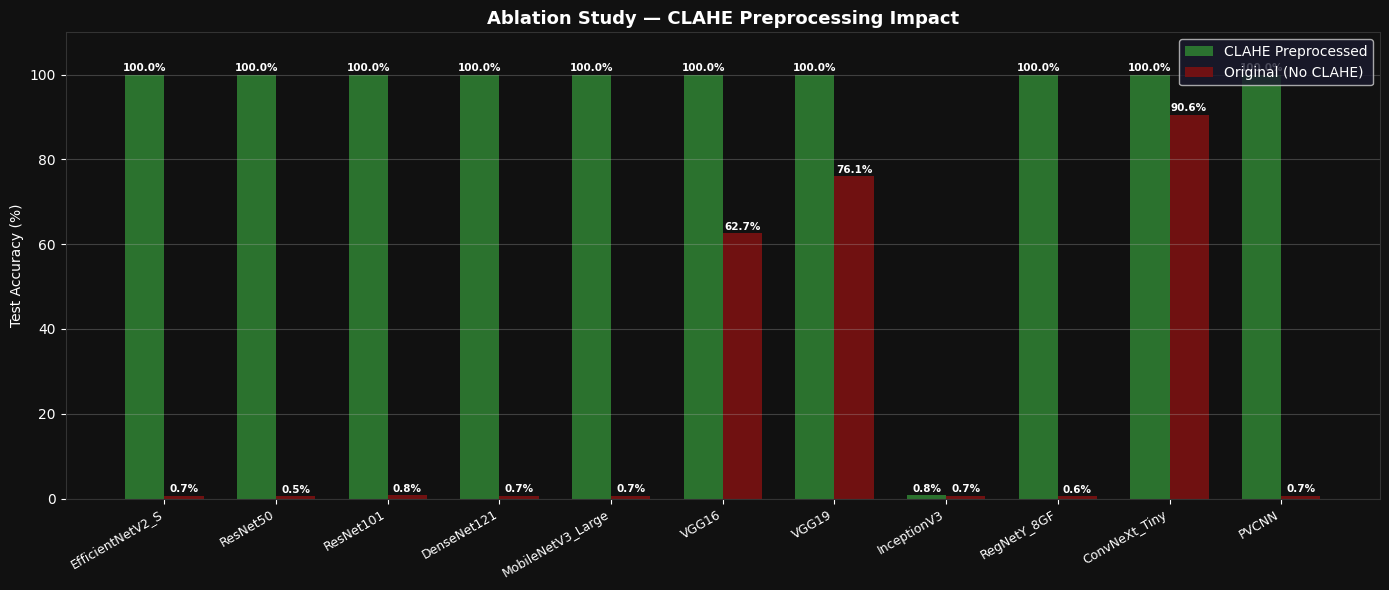

Saved: Outputs/PalmVein_V2/curves/ablation_preprocessing.png
                   Preprocessed  Original  Drop (%)
Model                                              
EfficientNetV2_S         100.00      0.67     99.33
ResNet50                 100.00      0.50     99.50
ResNet101                100.00      0.75     99.25
DenseNet121              100.00      0.67     99.33
MobileNetV3_Large        100.00      0.67     99.33
VGG16                    100.00     62.67     37.33
VGG19                    100.00     76.08     23.92
InceptionV3                0.83      0.67      0.17
RegNetY_8GF              100.00      0.58     99.42
ConvNeXt_Tiny            100.00     90.58      9.42
PVCNN                    100.00      0.67     99.33


In [54]:
import gc

ABLATION_BATCH_2 = ['InceptionV3', 'RegNetY_8GF', 'ConvNeXt_Tiny', 'PVCNN']

gc.collect()
torch.cuda.empty_cache()
print(f'Free VRAM: {torch.cuda.mem_get_info()[0]/1e9:.1f} GB')
print('='*60)
print('ABLATION — Batch 2 (4 models)')
print('='*60)

orig_inc_ds = torch.utils.data.Subset(
    PalmVeinDataset(DATASET_PATH, transform=T.Compose([
        T.Resize((299, 299)), T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])), test_ds.indices)
orig_inc_loader = DataLoader(orig_inc_ds, batch_size=8,
                             shuffle=False, num_workers=0, pin_memory=True)

for name in ABLATION_BATCH_2:
    if name not in trained_models: continue
    model  = trained_models[name]
    loader = orig_inc_loader if name == 'InceptionV3' else orig_test_loader

    y_true, y_pred_orig, _ = evaluate_standard(model, loader)
    acc_orig = (y_pred_orig == y_true).mean() * 100
    acc_pre  = (results[name][1] == results[name][0]).mean() * 100 if name in results else 0.0
    drop     = acc_pre - acc_orig

    ablation_rows.append({'Model': name, 'Preprocessed': round(acc_pre, 2),
                          'Original': round(acc_orig, 2), 'Drop (%)': round(drop, 2)})
    print(f'{name:20s} | Pre: {acc_pre:.2f}% | Orig: {acc_orig:.2f}% | Drop: {drop:+.2f}%')

    torch.cuda.empty_cache()
    gc.collect()

# ── Save + Plot ───────────────────────────────────────────────────────────────
df_ablation = pd.DataFrame(ablation_rows).set_index('Model')
df_ablation.to_csv(f'{OUTPUT_BASE}/reports/ablation_preprocessing.csv')

fig, ax = plt.subplots(figsize=(14, 6), facecolor='#111111')
ax.set_facecolor('#111111')

x     = np.arange(len(df_ablation))
width = 0.35
bars1 = ax.bar(x - width/2, df_ablation['Preprocessed'], width,
               label='CLAHE Preprocessed', color='#2E7D32', alpha=0.9)
bars2 = ax.bar(x + width/2, df_ablation['Original'],     width,
               label='Original (No CLAHE)', color='#7B1111', alpha=0.9)

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}%', ha='center', va='bottom',
            color='white', fontsize=7.5, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(df_ablation.index, rotation=30, ha='right', color='white', fontsize=9)
ax.set_ylabel('Test Accuracy (%)', color='white')
ax.set_title('Ablation Study — CLAHE Preprocessing Impact',
             color='white', fontsize=13, fontweight='bold')
ax.set_ylim(0, 110)
ax.tick_params(colors='white')
ax.legend(facecolor='#1a1a2e', labelcolor='white', fontsize=10)
ax.grid(True, axis='y', alpha=0.3)
for spine in ax.spines.values(): spine.set_edgecolor('#333333')

plt.tight_layout()
path = f'{OUTPUT_BASE}/curves/ablation_preprocessing.png'
plt.savefig(path, dpi=150, bbox_inches='tight', facecolor='#111111')
plt.show()
print(f'Saved: {path}')
print(df_ablation.to_string())

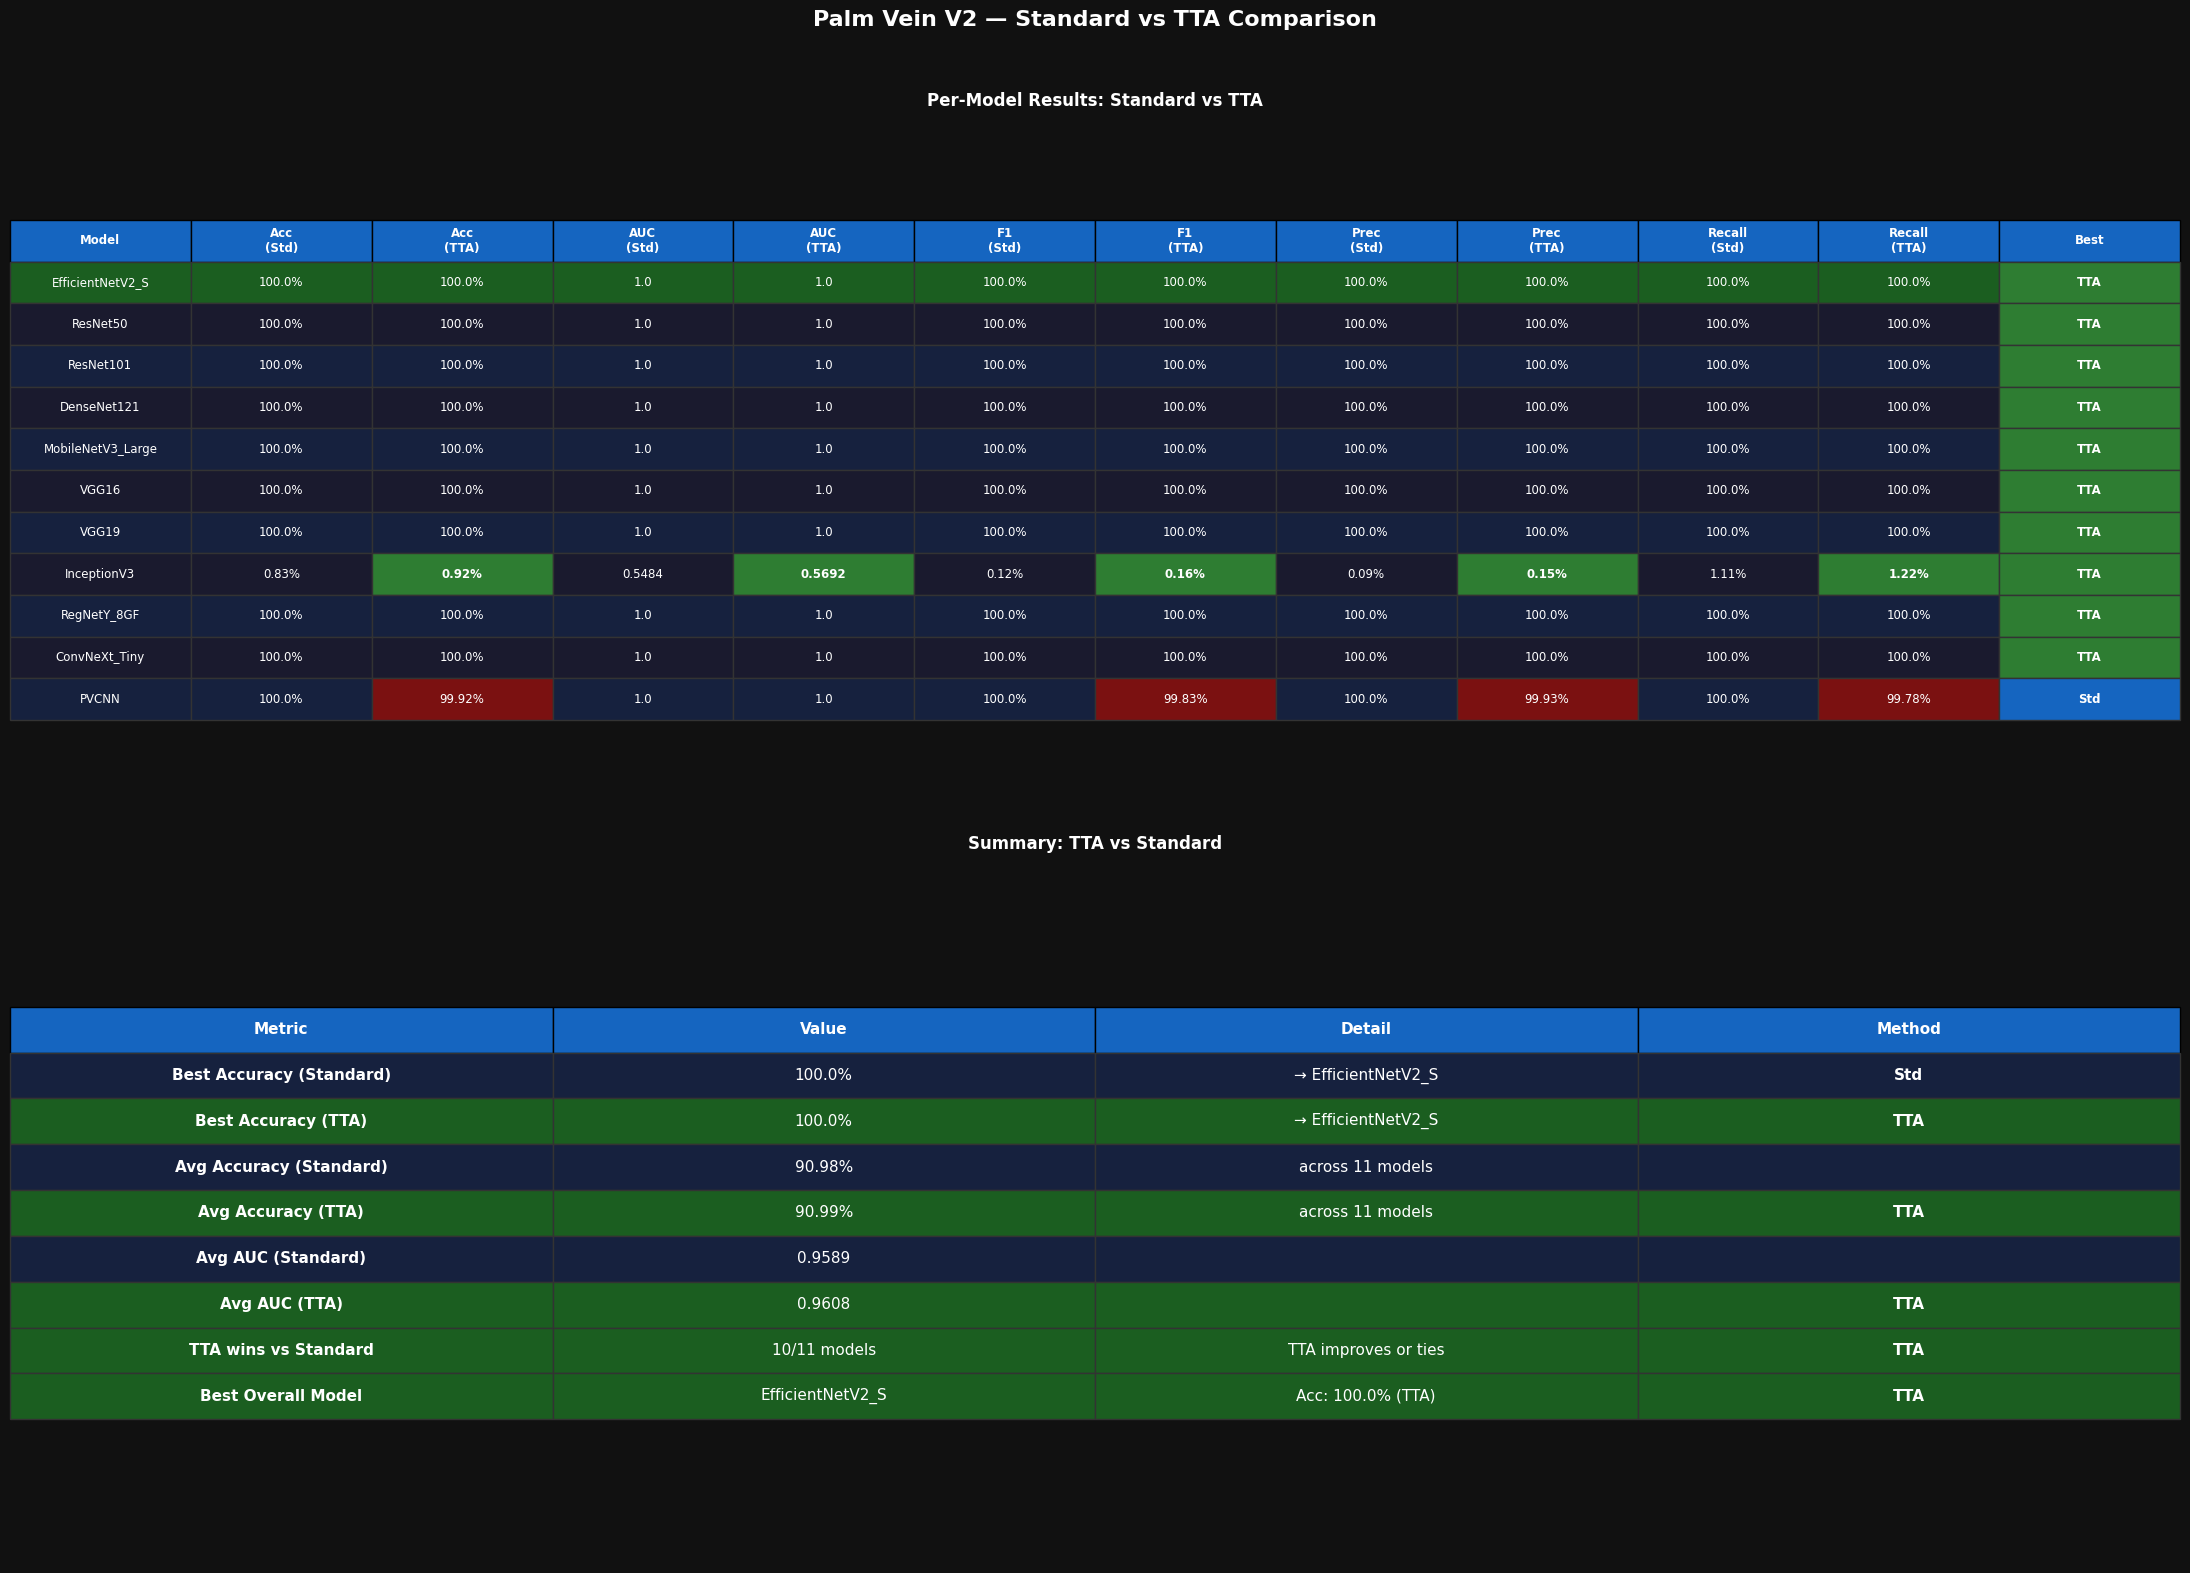

Saved: Outputs/PalmVein_V2/curves/tta_vs_standard_comparison.png
                   Acc (Std)  Acc (TTA)  AUC (Std)  AUC (TTA)
Model                                                        
EfficientNetV2_S      100.00     100.00     1.0000     1.0000
ResNet50              100.00     100.00     1.0000     1.0000
ResNet101             100.00     100.00     1.0000     1.0000
DenseNet121           100.00     100.00     1.0000     1.0000
MobileNetV3_Large     100.00     100.00     1.0000     1.0000
VGG16                 100.00     100.00     1.0000     1.0000
VGG19                 100.00     100.00     1.0000     1.0000
InceptionV3             0.83       0.92     0.5484     0.5692
RegNetY_8GF           100.00     100.00     1.0000     1.0000
ConvNeXt_Tiny         100.00     100.00     1.0000     1.0000
PVCNN                 100.00      99.92     1.0000     1.0000


In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.preprocessing import label_binarize
import gc

rows = []

for name, (y_true, y_pred_std, y_prob_std, y_pred_tta, y_prob_tta) in results.items():
    y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))

    rep_std = classification_report(y_true, y_pred_std, output_dict=True, zero_division=0)
    rep_tta = classification_report(y_true, y_pred_tta, output_dict=True, zero_division=0)

    try:
        auc_std = roc_auc_score(y_bin, y_prob_std, average='macro', multi_class='ovr')
        auc_tta = roc_auc_score(y_bin, y_prob_tta, average='macro', multi_class='ovr')
    except Exception:
        auc_std = auc_tta = 0.0

    rows.append({
        'Model':        name,
        'Acc (Std)':    round(rep_std['accuracy'] * 100, 2),
        'Acc (TTA)':    round(rep_tta['accuracy'] * 100, 2),
        'AUC (Std)':    round(auc_std, 4),
        'AUC (TTA)':    round(auc_tta, 4),
        'F1 (Std)':     round(rep_std['macro avg']['f1-score'] * 100, 2),
        'F1 (TTA)':     round(rep_tta['macro avg']['f1-score'] * 100, 2),
        'Prec (Std)':   round(rep_std['macro avg']['precision'] * 100, 2),
        'Prec (TTA)':   round(rep_tta['macro avg']['precision'] * 100, 2),
        'Recall (Std)': round(rep_std['macro avg']['recall'] * 100, 2),
        'Recall (TTA)': round(rep_tta['macro avg']['recall'] * 100, 2),
    })

df = pd.DataFrame(rows).set_index('Model')
best_model = df['Acc (TTA)'].idxmax()

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(22, 16), facecolor='#111111')
fig.suptitle('Palm Vein V2 — Standard vs TTA Comparison', fontsize=16,
             fontweight='bold', color='white', y=0.98)

# ── TOP TABLE ─────────────────────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor('#111111')
ax.axis('off')

col_labels = ['Model', 'Acc\n(Std)', 'Acc\n(TTA)', 'AUC\n(Std)', 'AUC\n(TTA)',
              'F1\n(Std)', 'F1\n(TTA)', 'Prec\n(Std)', 'Prec\n(TTA)',
              'Recall\n(Std)', 'Recall\n(TTA)', 'Best']

table_data = []
for name, row in df.iterrows():
    best = 'TTA' if row['Acc (TTA)'] >= row['Acc (Std)'] else 'Std'
    table_data.append([
        name,
        f"{row['Acc (Std)']}%",   f"{row['Acc (TTA)']}%",
        f"{row['AUC (Std)']}",    f"{row['AUC (TTA)']}",
        f"{row['F1 (Std)']}%",    f"{row['F1 (TTA)']}%",
        f"{row['Prec (Std)']}%",  f"{row['Prec (TTA)']}%",
        f"{row['Recall (Std)']}%",f"{row['Recall (TTA)']}%",
        best
    ])

tbl = ax.table(cellText=table_data, colLabels=col_labels,
               loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
tbl.scale(1, 2.0)

for j in range(len(col_labels)):
    tbl[0, j].set_facecolor('#1565C0')
    tbl[0, j].set_text_props(color='white', fontweight='bold')

for i, (name, row) in enumerate(df.iterrows(), start=1):
    for j in range(len(col_labels)):
        cell = tbl[i, j]
        base_color = '#1B5E20' if name == best_model else (
                     '#1a1a2e' if i % 2 == 0 else '#16213e')
        cell.set_facecolor(base_color)
        cell.set_text_props(color='white')

        # Green if TTA > Std
        if j in [2, 4, 6, 8, 10]:
            try:
                sv = float(str(table_data[i-1][j-1]).replace('%',''))
                tv = float(str(table_data[i-1][j]).replace('%',''))
                if tv > sv:
                    cell.set_facecolor('#2E7D32')
                    cell.set_text_props(color='white', fontweight='bold')
                elif tv < sv:
                    cell.set_facecolor('#7B1111')
            except Exception:
                pass

        if j == len(col_labels) - 1:
            cell.set_facecolor('#2E7D32' if table_data[i-1][j]=='TTA' else '#1565C0')
            cell.set_text_props(color='white', fontweight='bold')

        cell.set_edgecolor('#333333')

ax.set_title('Per-Model Results: Standard vs TTA', color='white',
             fontsize=12, fontweight='bold', pad=10)

# ── BOTTOM SUMMARY TABLE ──────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#111111')
ax2.axis('off')

tta_wins = sum(1 for _, r in df.iterrows() if r['Acc (TTA)'] >= r['Acc (Std)'])

summary_data = [
    ['Best Accuracy (Standard)', f"{df['Acc (Std)'].max()}%",  f"→ {df['Acc (Std)'].idxmax()}", 'Std'],
    ['Best Accuracy (TTA)',      f"{df['Acc (TTA)'].max()}%",  f"→ {df['Acc (TTA)'].idxmax()}", 'TTA'],
    ['Avg Accuracy (Standard)',  f"{df['Acc (Std)'].mean():.2f}%", f"across {len(df)} models",  ''],
    ['Avg Accuracy (TTA)',       f"{df['Acc (TTA)'].mean():.2f}%", f"across {len(df)} models",  'TTA'],
    ['Avg AUC (Standard)',       f"{df['AUC (Std)'].mean():.4f}", '', ''],
    ['Avg AUC (TTA)',            f"{df['AUC (TTA)'].mean():.4f}", '', 'TTA'],
    ['TTA wins vs Standard',     f"{tta_wins}/{len(df)} models", 'TTA improves or ties', 'TTA'],
    ['Best Overall Model',       best_model, f"Acc: {df.loc[best_model,'Acc (TTA)']}% (TTA)", 'TTA'],
]

tbl2 = ax2.table(cellText=summary_data,
                 colLabels=['Metric', 'Value', 'Detail', 'Method'],
                 loc='center', cellLoc='center')
tbl2.auto_set_font_size(False)
tbl2.set_fontsize(11)
tbl2.scale(1, 2.2)

for j in range(4):
    tbl2[0, j].set_facecolor('#1565C0')
    tbl2[0, j].set_text_props(color='white', fontweight='bold')

for i in range(1, len(summary_data) + 1):
    method = summary_data[i-1][3]
    for j in range(4):
        cell = tbl2[i, j]
        cell.set_facecolor('#1B5E20' if method == 'TTA' else
                           ('#1a1a2e' if i % 2 == 0 else '#16213e'))
        cell.set_text_props(color='white',
                            fontweight='bold' if j in [0, 3] else 'normal')
        cell.set_edgecolor('#333333')

ax2.set_title('Summary: TTA vs Standard', color='white',
              fontsize=12, fontweight='bold', pad=10)

plt.tight_layout(rect=[0, 0, 1, 0.96])
save_path = f'{OUTPUT_BASE}/curves/tta_vs_standard_comparison.png'
plt.savefig(save_path, dpi=150, bbox_inches='tight', facecolor='#111111')
plt.show()
print(f'Saved: {save_path}')
print(df[['Acc (Std)', 'Acc (TTA)', 'AUC (Std)', 'AUC (TTA)']].to_string())

gc.collect()
torch.cuda.empty_cache()

## Cell · Score-Level Ensemble Fusion

Averages the softmax probability distributions from all trained models.  
The final prediction is the class with the highest **average probability** across all models.

This outperforms majority voting (V1) because it uses the full confidence distribution rather than just the argmax.

Both **standard** and **TTA** fusion are computed.

In [56]:
# ── Standard Fusion ───────────────────────────────────────────────────────────
# Average softmax probabilities across all models
all_probs_std = np.stack([results[n][2] for n in results], axis=0).mean(axis=0)
y_true_fusion = results[list(results.keys())[0]][0]
y_pred_fusion_std = all_probs_std.argmax(axis=1)
acc_fusion_std = (y_pred_fusion_std == y_true_fusion).mean() * 100

# ── TTA Fusion ────────────────────────────────────────────────────────────────
all_probs_tta = np.stack([results[n][4] for n in results], axis=0).mean(axis=0)
y_pred_fusion_tta = all_probs_tta.argmax(axis=1)
acc_fusion_tta = (y_pred_fusion_tta == y_true_fusion).mean() * 100

print('='*60)
print('SCORE-LEVEL ENSEMBLE FUSION RESULTS')
print('='*60)
print(f'Standard Fusion: {acc_fusion_std:.2f}%')
print(f'TTA Fusion:      {acc_fusion_tta:.2f}%  (Δ {acc_fusion_tta-acc_fusion_std:+.2f}%)')


SCORE-LEVEL ENSEMBLE FUSION RESULTS
Standard Fusion: 100.00%
TTA Fusion:      100.00%  (Δ +0.00%)


## Cell · Classification Reports

Per-class precision, recall, F1-score for every model + ensemble.  
Saved as CSV to `Outputs/PalmVein_V2/reports/`.

In [57]:
os.makedirs(f'{OUTPUT_BASE}/reports', exist_ok=True)

summary_rows = []

for name, (y_true, y_pred_std, y_prob_std, y_pred_tta, y_prob_tta) in results.items():
    for tag, y_pred in [('Standard', y_pred_std), ('TTA', y_pred_tta)]:
        rep = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
        pd.DataFrame(rep).T.to_csv(f'{OUTPUT_BASE}/reports/{name}_{tag}_report.csv')
        summary_rows.append({
            'Model': name, 'Mode': tag,
            'Accuracy(%)':   round(rep['accuracy']*100, 2),
            'Macro F1(%)':   round(rep['macro avg']['f1-score']*100, 2),
            'Macro Prec(%)': round(rep['macro avg']['precision']*100, 2),
            'Macro Rec(%)':  round(rep['macro avg']['recall']*100, 2),
        })
        print(f'{name} [{tag}] | Acc: {rep["accuracy"]*100:.2f}% | '
              f'F1: {rep["macro avg"]["f1-score"]*100:.2f}%')

# Add fusion rows
for tag, y_pred in [('Standard', y_pred_fusion_std), ('TTA', y_pred_fusion_tta)]:
    rep = classification_report(y_true_fusion, y_pred, target_names=CLASS_NAMES, output_dict=True)
    summary_rows.append({
        'Model': 'ENSEMBLE', 'Mode': tag,
        'Accuracy(%)':   round(rep['accuracy']*100, 2),
        'Macro F1(%)':   round(rep['macro avg']['f1-score']*100, 2),
        'Macro Prec(%)': round(rep['macro avg']['precision']*100, 2),
        'Macro Rec(%)':  round(rep['macro avg']['recall']*100, 2),
    })
    print(f'ENSEMBLE [{tag}] | Acc: {rep["accuracy"]*100:.2f}% | '
          f'F1: {rep["macro avg"]["f1-score"]*100:.2f}%')

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(f'{OUTPUT_BASE}/reports/summary.csv', index=False)
print('\n', df_summary.to_string(index=False))


EfficientNetV2_S [Standard] | Acc: 100.00% | F1: 100.00%
EfficientNetV2_S [TTA] | Acc: 100.00% | F1: 100.00%
ResNet50 [Standard] | Acc: 100.00% | F1: 100.00%
ResNet50 [TTA] | Acc: 100.00% | F1: 100.00%
ResNet101 [Standard] | Acc: 100.00% | F1: 100.00%
ResNet101 [TTA] | Acc: 100.00% | F1: 100.00%
DenseNet121 [Standard] | Acc: 100.00% | F1: 100.00%
DenseNet121 [TTA] | Acc: 100.00% | F1: 100.00%
MobileNetV3_Large [Standard] | Acc: 100.00% | F1: 100.00%
MobileNetV3_Large [TTA] | Acc: 100.00% | F1: 100.00%
VGG16 [Standard] | Acc: 100.00% | F1: 100.00%
VGG16 [TTA] | Acc: 100.00% | F1: 100.00%
VGG19 [Standard] | Acc: 100.00% | F1: 100.00%
VGG19 [TTA] | Acc: 100.00% | F1: 100.00%
InceptionV3 [Standard] | Acc: 0.83% | F1: 0.12%
InceptionV3 [TTA] | Acc: 0.92% | F1: 0.16%
RegNetY_8GF [Standard] | Acc: 100.00% | F1: 100.00%
RegNetY_8GF [TTA] | Acc: 100.00% | F1: 100.00%
ConvNeXt_Tiny [Standard] | Acc: 100.00% | F1: 100.00%
ConvNeXt_Tiny [TTA] | Acc: 100.00% | F1: 100.00%
PVCNN [Standard] | Acc: 10

c:\Users\SMHC\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\SMHC\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\SMHC\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

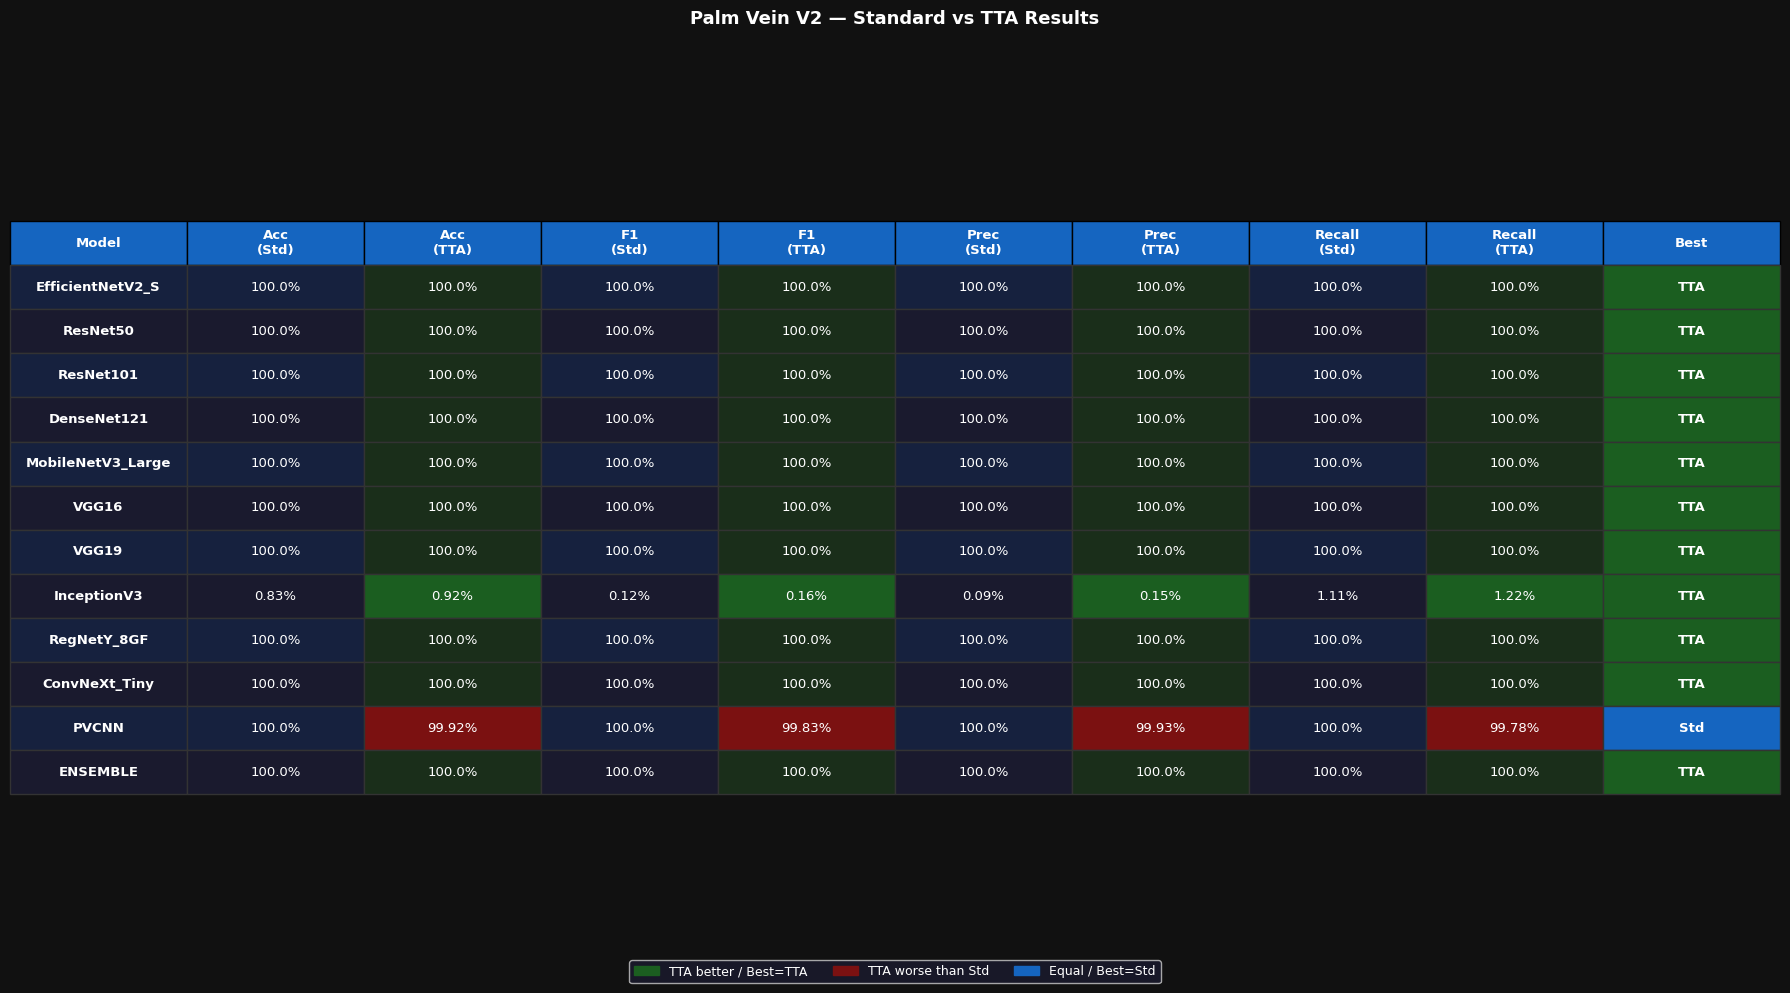

Saved: Outputs/PalmVein_V2/curves/standard_vs_tta_table.png


In [58]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(18, 10), facecolor='#111111')
ax.set_facecolor('#111111')
ax.axis('off')

# Pivot to one row per model
df_std = df_summary[df_summary['Mode']=='Standard'].set_index('Model')
df_tta = df_summary[df_summary['Mode']=='TTA'].set_index('Model')
models_list = df_std.index.tolist()

col_labels = ['Model', 'Acc\n(Std)', 'Acc\n(TTA)', 'F1\n(Std)', 'F1\n(TTA)',
              'Prec\n(Std)', 'Prec\n(TTA)', 'Recall\n(Std)', 'Recall\n(TTA)', 'Best']

table_data = []
for m in models_list:
    std = df_std.loc[m]
    tta = df_tta.loc[m]
    best = 'TTA' if tta['Accuracy(%)'] >= std['Accuracy(%)'] else 'Std'
    table_data.append([
        m,
        f"{std['Accuracy(%)']}%",  f"{tta['Accuracy(%)']}%",
        f"{std['Macro F1(%)']}%",  f"{tta['Macro F1(%)']}%",
        f"{std['Macro Prec(%)']}%",f"{tta['Macro Prec(%)']}%",
        f"{std['Macro Rec(%)']}%", f"{tta['Macro Rec(%)']}%",
        best
    ])

tbl = ax.table(cellText=table_data, colLabels=col_labels,
               loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9.5)
tbl.scale(1, 2.2)

# Header
for j in range(len(col_labels)):
    tbl[0, j].set_facecolor('#1565C0')
    tbl[0, j].set_text_props(color='white', fontweight='bold')

# Rows
for i, row in enumerate(table_data, start=1):
    for j in range(len(col_labels)):
        cell = tbl[i, j]
        # TTA better than Std cols → green
        if j in [2, 4, 6, 8]:
            std_v = float(row[j-1].replace('%',''))
            tta_v = float(row[j].replace('%',''))
            if tta_v > std_v:
                cell.set_facecolor('#1B5E20')
            elif tta_v == std_v:
                cell.set_facecolor('#1a2e1a')
            else:
                cell.set_facecolor('#7B1111')
        elif j == len(col_labels)-1:
            cell.set_facecolor('#1B5E20' if row[j]=='TTA' else '#1565C0')
        else:
            cell.set_facecolor('#1a1a2e' if i%2==0 else '#16213e')
        cell.set_text_props(color='white',
                            fontweight='bold' if j in [0, len(col_labels)-1] else 'normal')
        cell.set_edgecolor('#333333')

ax.set_title('Palm Vein V2 — Standard vs TTA Results',
             color='white', fontsize=13, fontweight='bold', pad=15)

# Legend
from matplotlib.patches import Patch
legend = [Patch(color='#1B5E20', label='TTA better / Best=TTA'),
          Patch(color='#7B1111', label='TTA worse than Std'),
          Patch(color='#1565C0', label='Equal / Best=Std')]
ax.legend(handles=legend, loc='lower center', ncol=3,
          facecolor='#1a1a2e', labelcolor='white', fontsize=9,
          bbox_to_anchor=(0.5, -0.02))

plt.tight_layout()
path = f'{OUTPUT_BASE}/curves/standard_vs_tta_table.png'
plt.savefig(path, dpi=150, bbox_inches='tight', facecolor='#111111')
plt.show()
print(f'Saved: {path}')

## Cell · Confusion Matrices

Normalised confusion matrix for each model (TTA predictions).  
Perfect diagonal = all classes correctly identified.

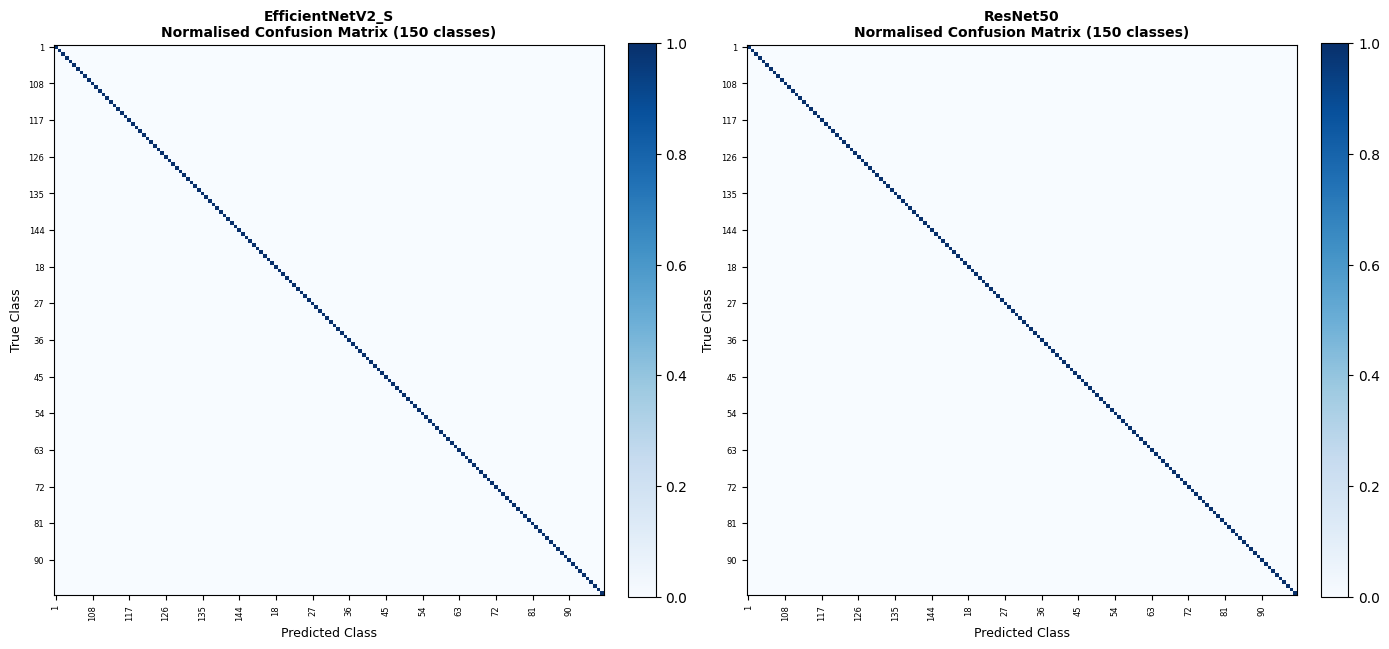

Saved: Outputs/PalmVein_V2/confusion/EfficientNetV2_S_ResNet50_confusion.png


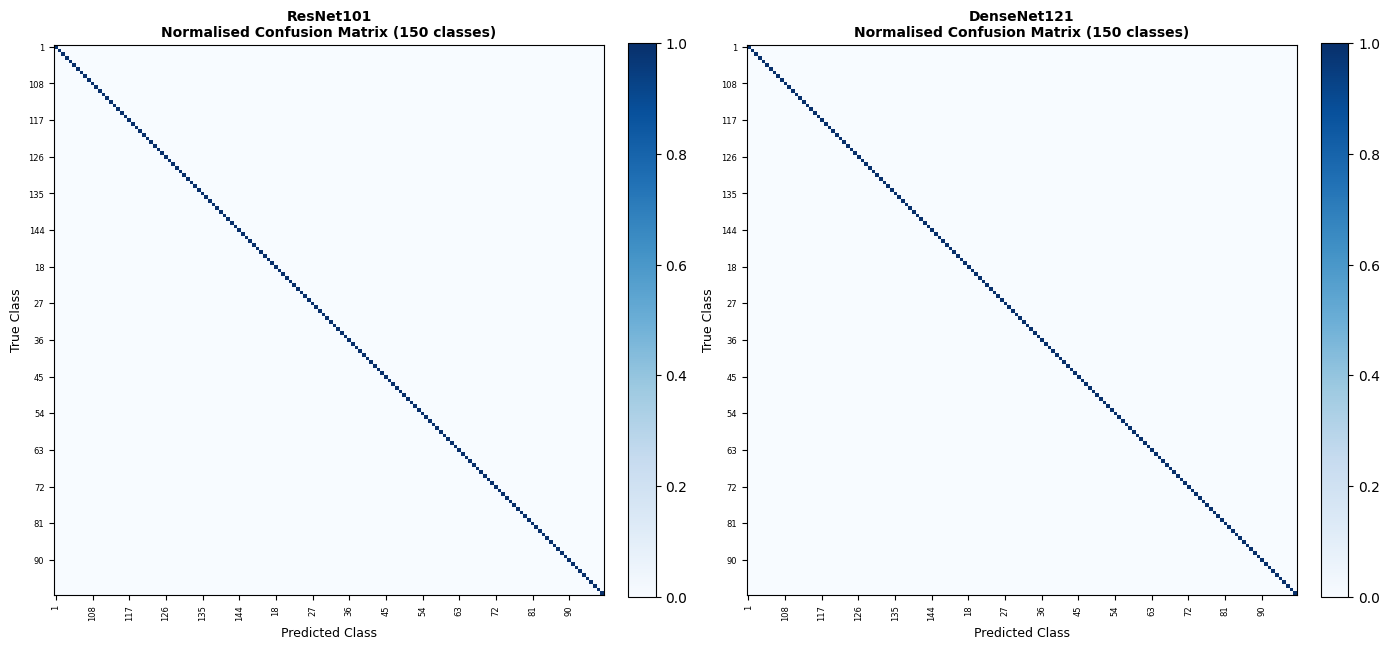

Saved: Outputs/PalmVein_V2/confusion/ResNet101_DenseNet121_confusion.png


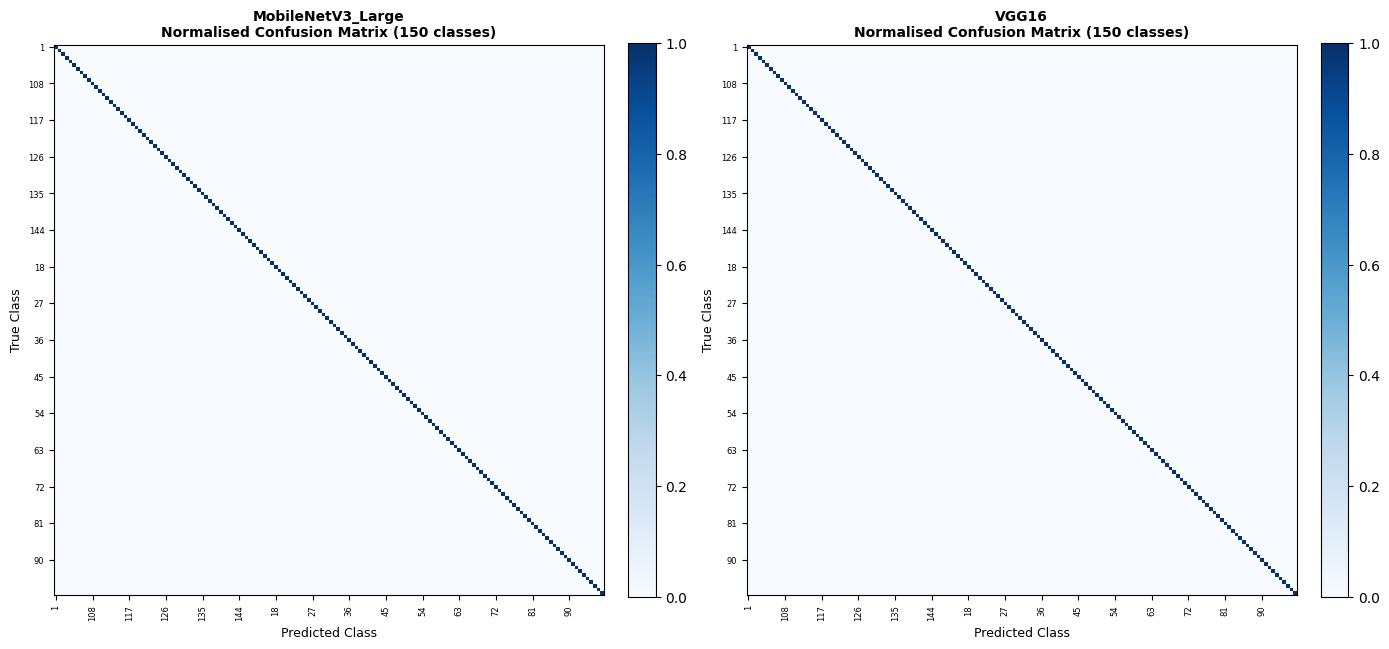

Saved: Outputs/PalmVein_V2/confusion/MobileNetV3_Large_VGG16_confusion.png


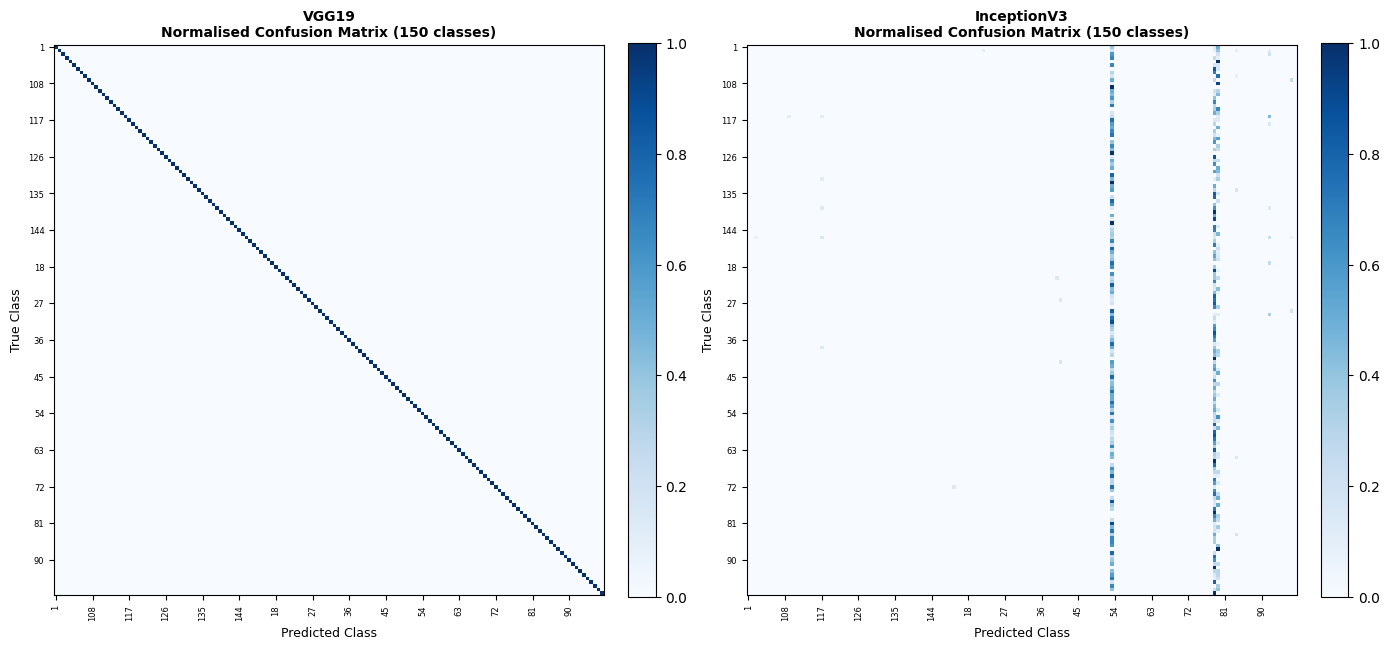

Saved: Outputs/PalmVein_V2/confusion/VGG19_InceptionV3_confusion.png


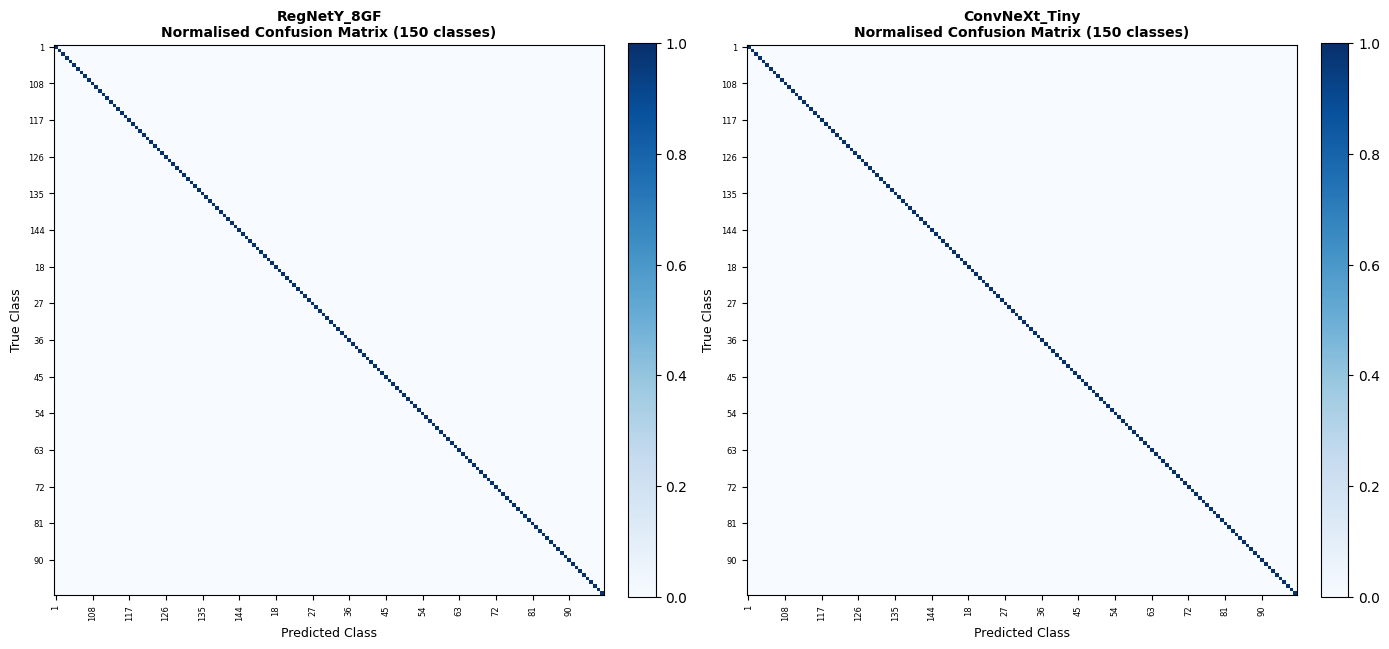

Saved: Outputs/PalmVein_V2/confusion/RegNetY_8GF_ConvNeXt_Tiny_confusion.png


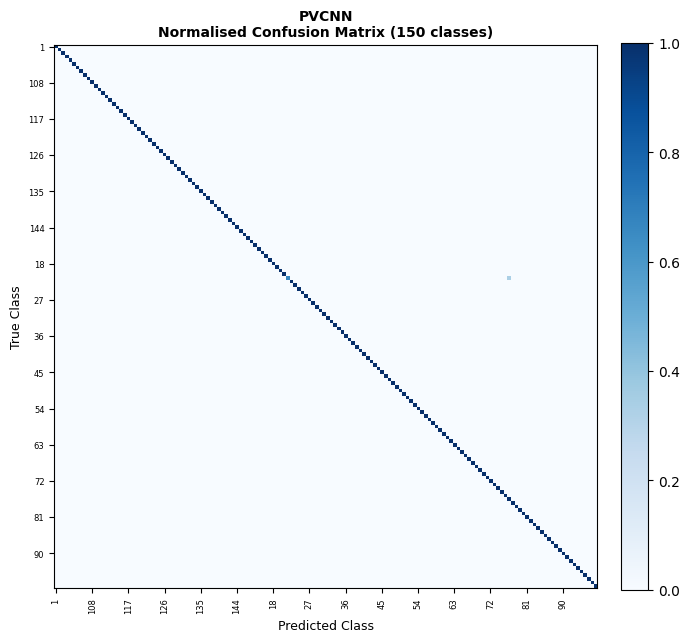

Saved: Outputs/PalmVein_V2/confusion/PVCNN__confusion.png


In [59]:
names_list = list(results.keys())

for i in range(0, len(names_list), 2):
    batch = names_list[i:i+2]
    fig, axes = plt.subplots(1, len(batch), figsize=(14 * len(batch) // 2, 10))
    if len(batch) == 1:
        axes = [axes]

    for ax, name in zip(axes, batch):
        y_true, _, _, y_pred_tta, _ = results[name]
        cm      = confusion_matrix(y_true, y_pred_tta)
        cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

        im = ax.imshow(cm_norm, cmap='Blues', interpolation='nearest')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(f'{name}\nNormalised Confusion Matrix ({NUM_CLASSES} classes)',
                     fontsize=10, fontweight='bold')
        ax.set_xlabel('Predicted Class', fontsize=9)
        ax.set_ylabel('True Class', fontsize=9)

        step = max(1, NUM_CLASSES // 15)
        ticks = range(0, NUM_CLASSES, step)
        ax.set_xticks(ticks); ax.set_yticks(ticks)
        ax.set_xticklabels([CLASS_NAMES[i] for i in ticks], rotation=90, fontsize=6)
        ax.set_yticklabels([CLASS_NAMES[i] for i in ticks], fontsize=6)

    plt.tight_layout()
    path = f'{OUTPUT_BASE}/confusion/{batch[0]}_{"_".join(batch[1:])}_confusion.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {path}')

## Cell · ROC Curves

Macro-average ROC curve + AUC distribution for each model (TTA probabilities).  
AUC = 1.0 is the perfect classifier.

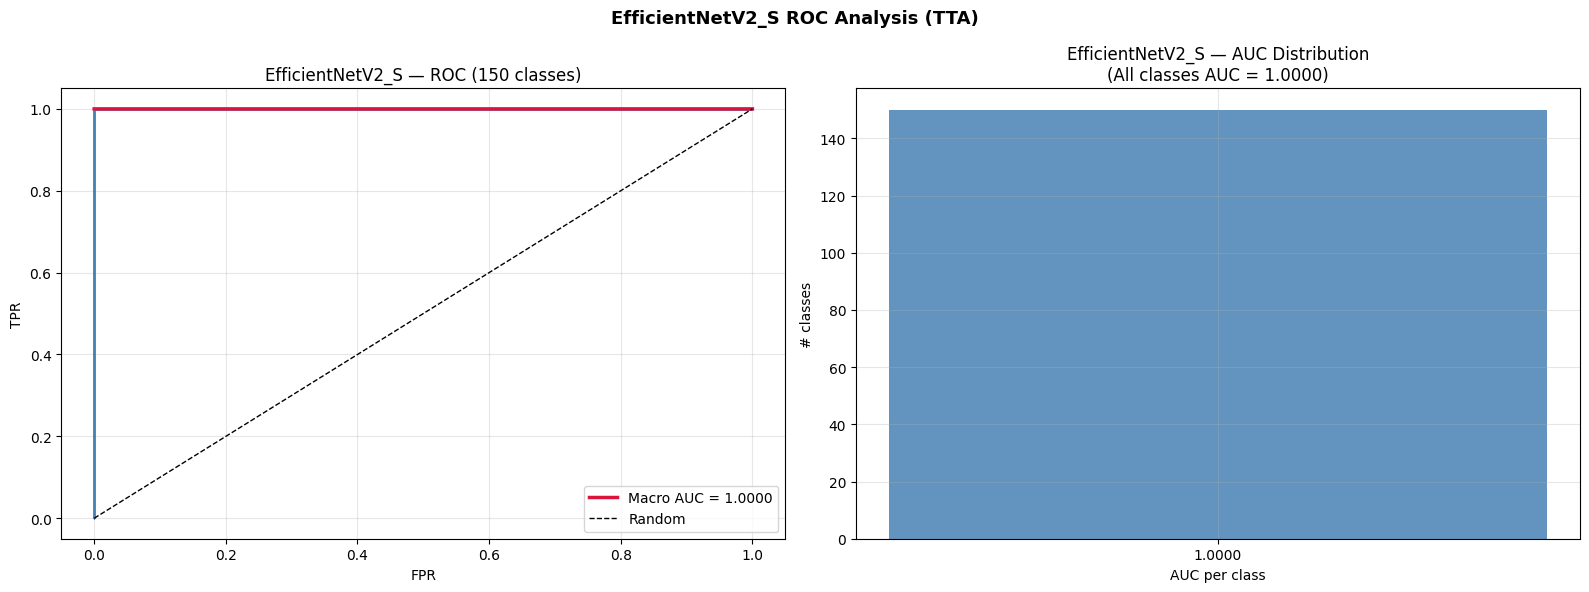

Saved: Outputs/PalmVein_V2/roc/EfficientNetV2_S_roc.png  |  Macro AUC: 1.0000


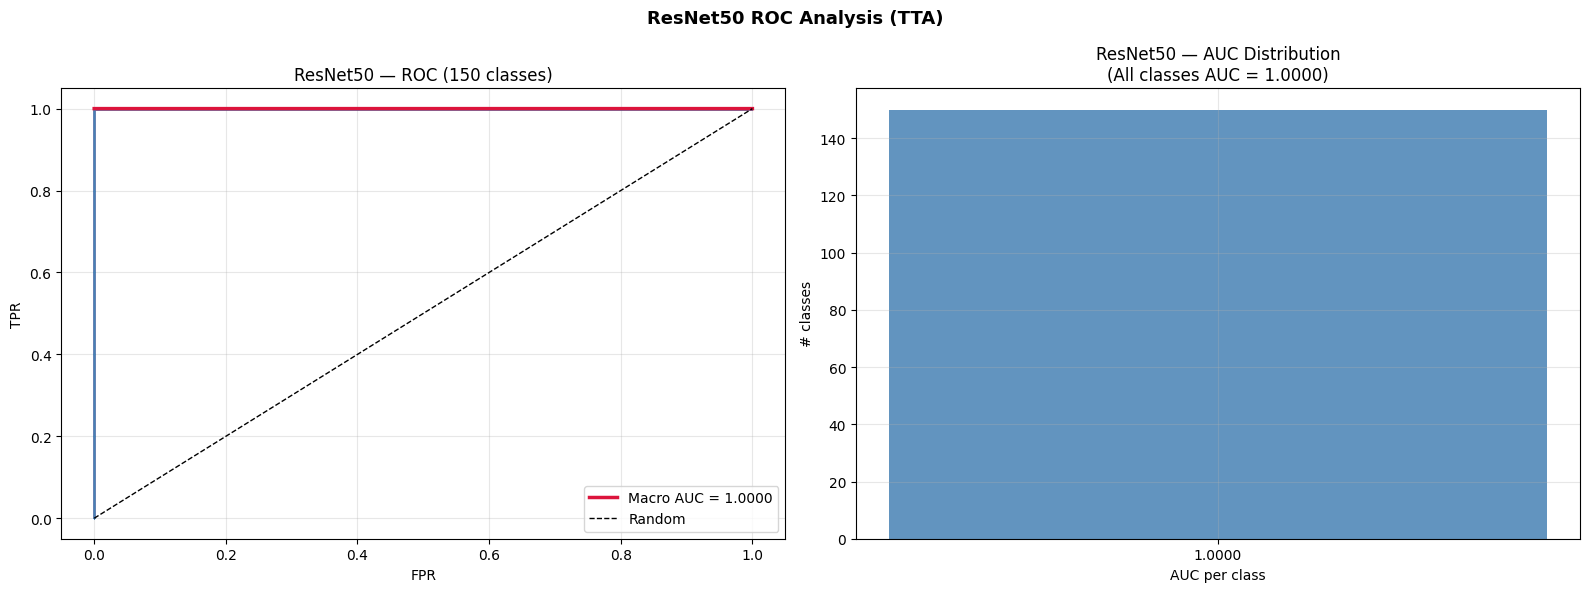

Saved: Outputs/PalmVein_V2/roc/ResNet50_roc.png  |  Macro AUC: 1.0000


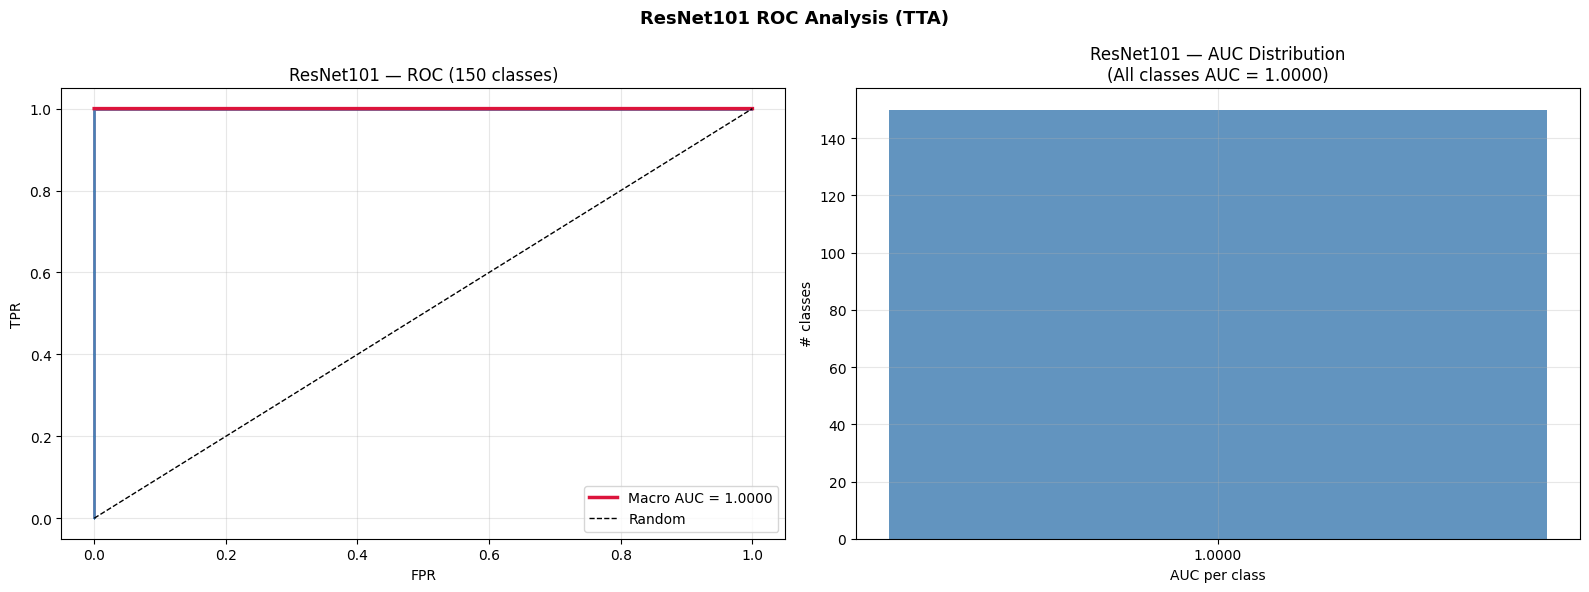

Saved: Outputs/PalmVein_V2/roc/ResNet101_roc.png  |  Macro AUC: 1.0000


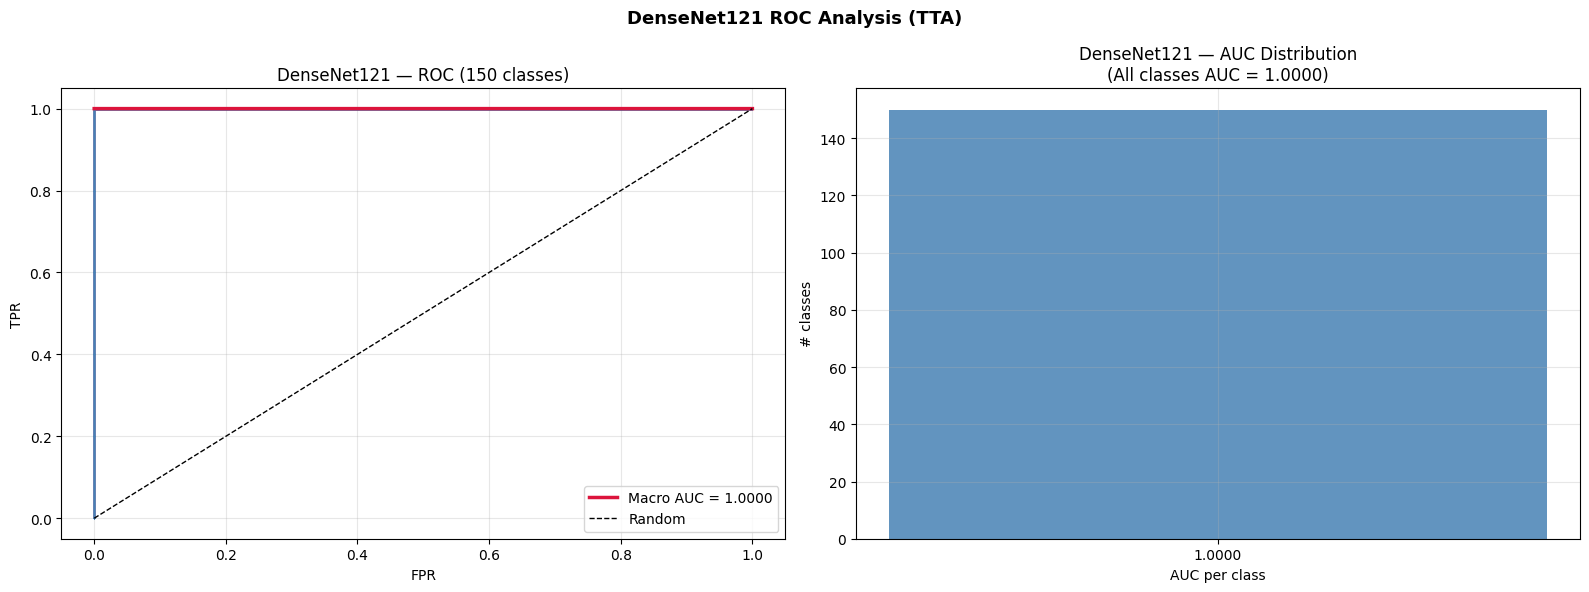

Saved: Outputs/PalmVein_V2/roc/DenseNet121_roc.png  |  Macro AUC: 1.0000


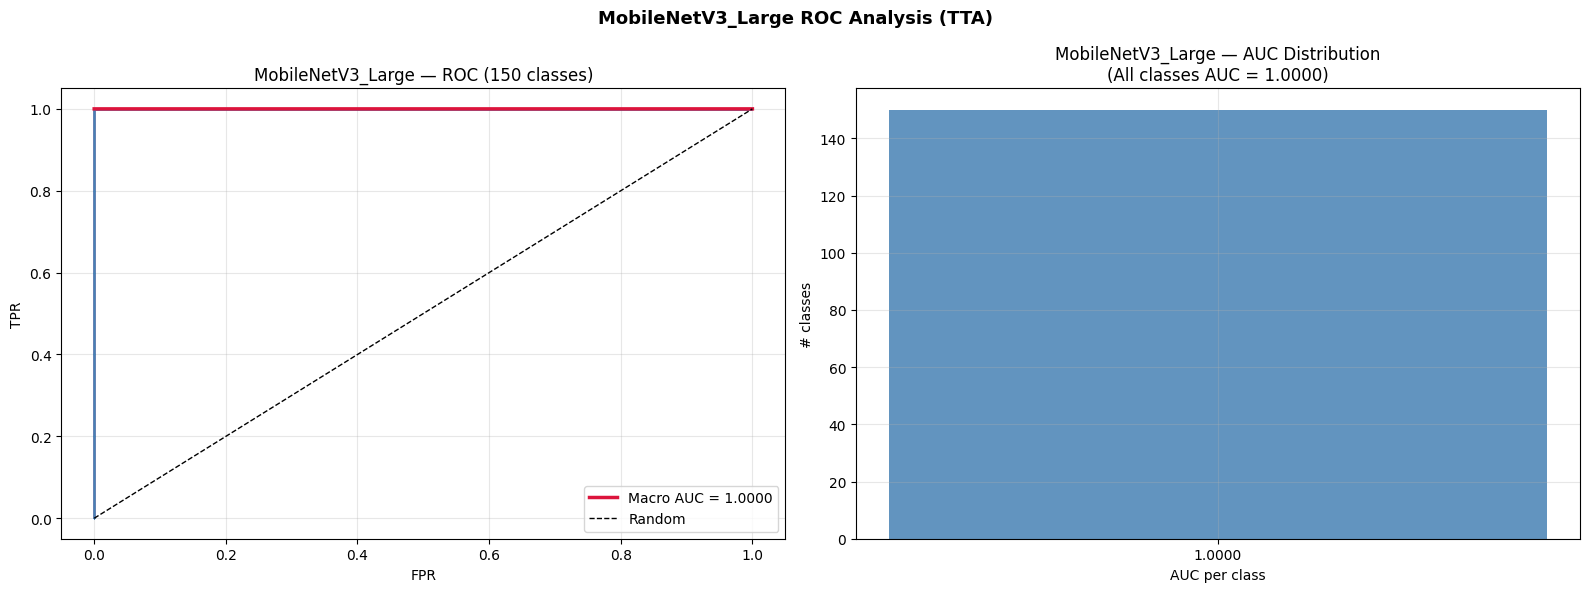

Saved: Outputs/PalmVein_V2/roc/MobileNetV3_Large_roc.png  |  Macro AUC: 1.0000


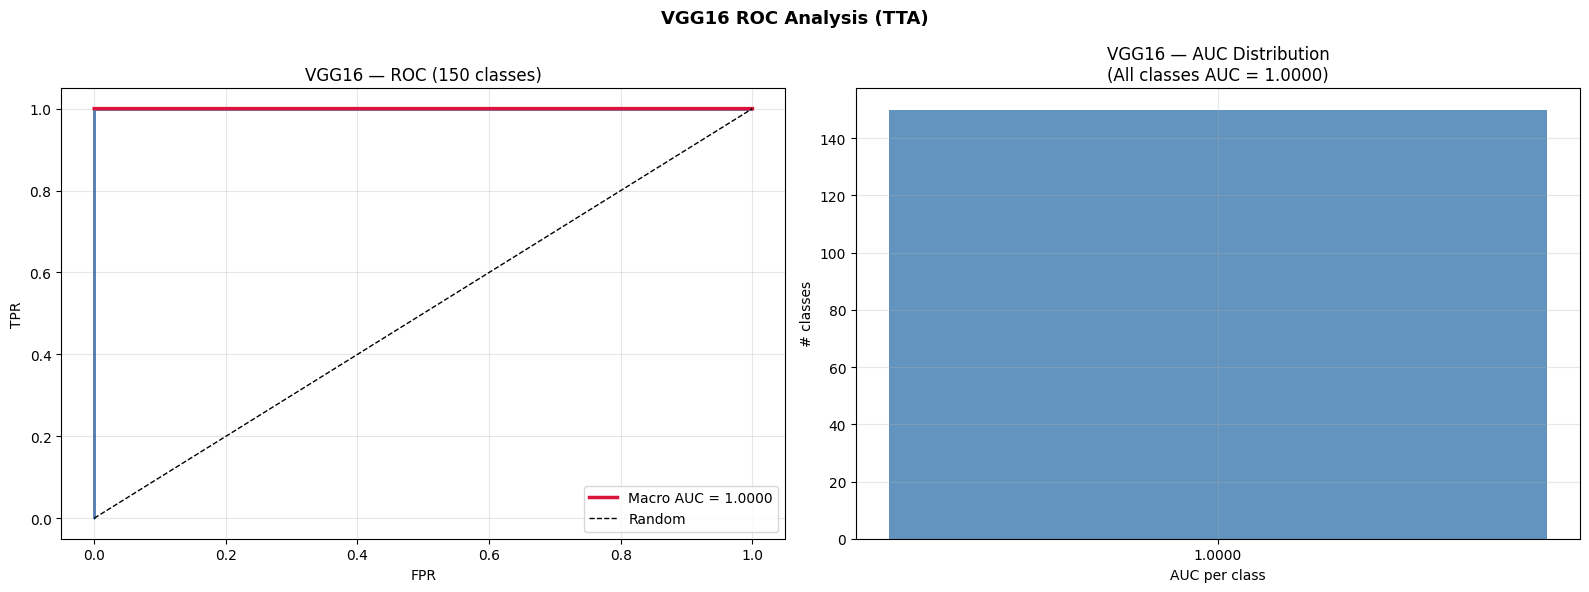

Saved: Outputs/PalmVein_V2/roc/VGG16_roc.png  |  Macro AUC: 1.0000


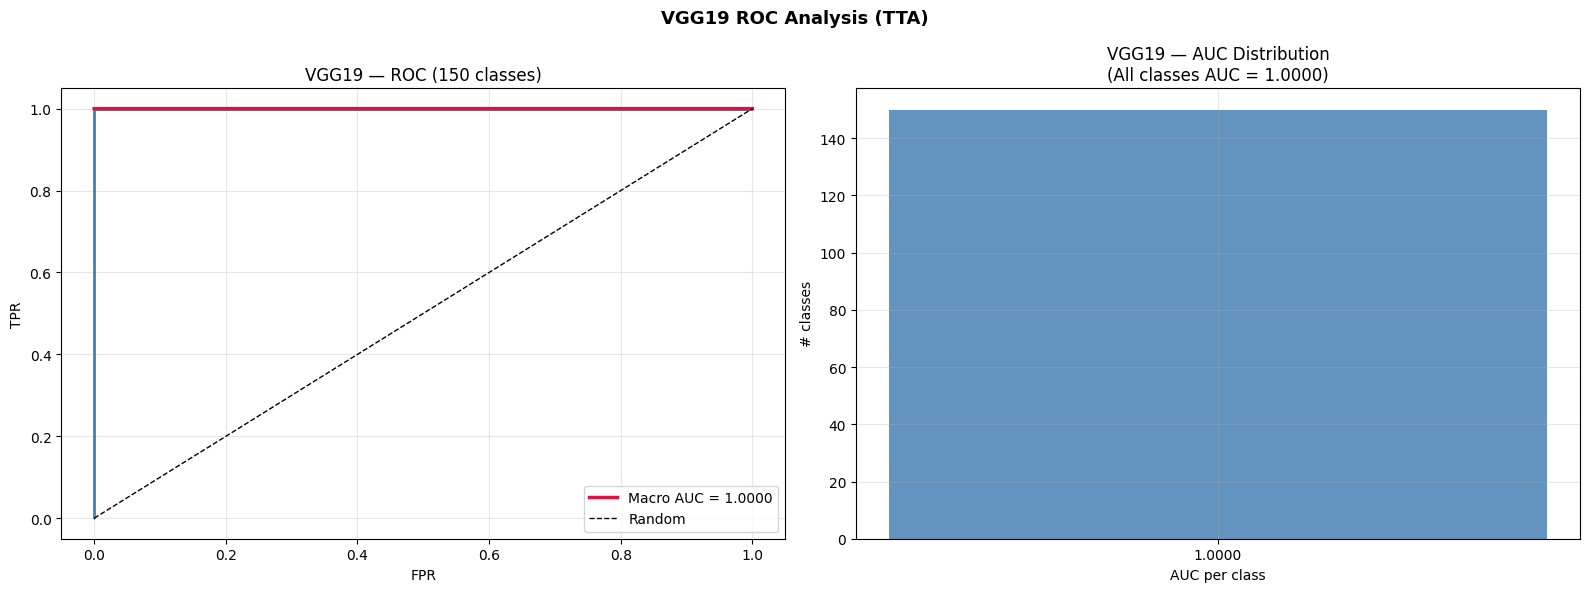

Saved: Outputs/PalmVein_V2/roc/VGG19_roc.png  |  Macro AUC: 1.0000


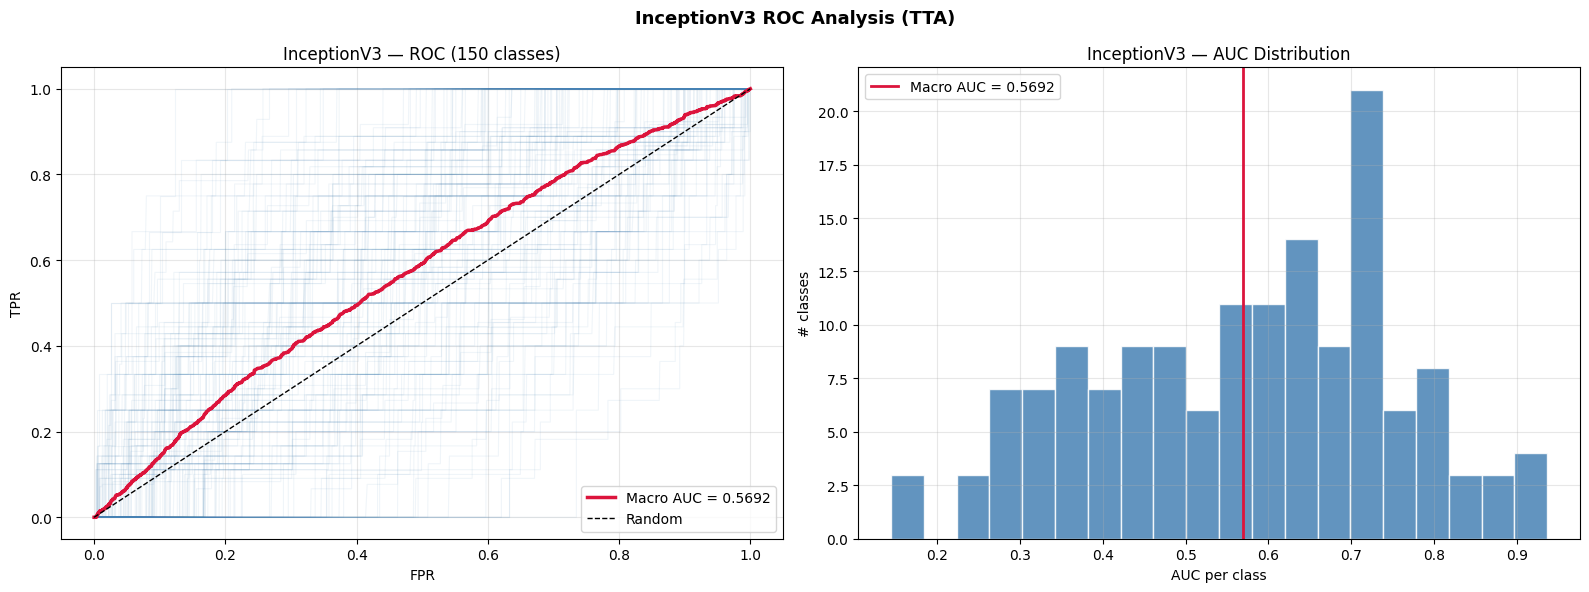

Saved: Outputs/PalmVein_V2/roc/InceptionV3_roc.png  |  Macro AUC: 0.5692


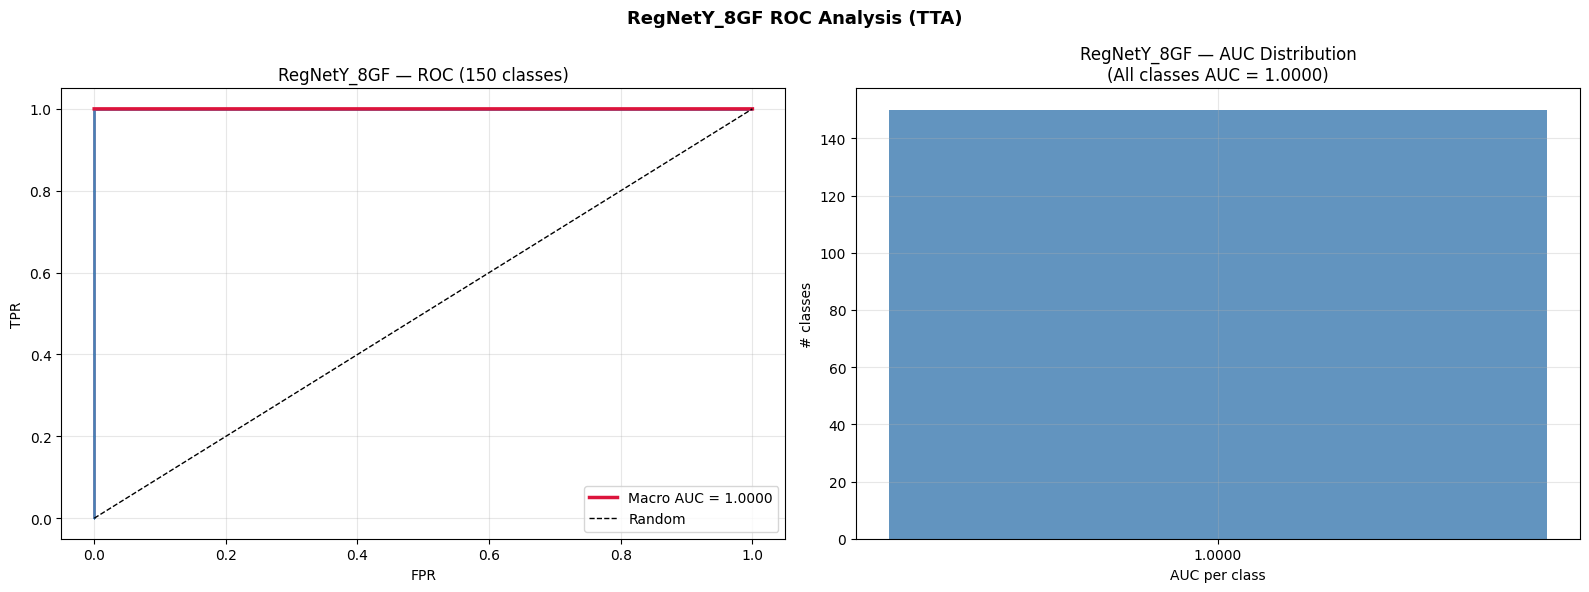

Saved: Outputs/PalmVein_V2/roc/RegNetY_8GF_roc.png  |  Macro AUC: 1.0000


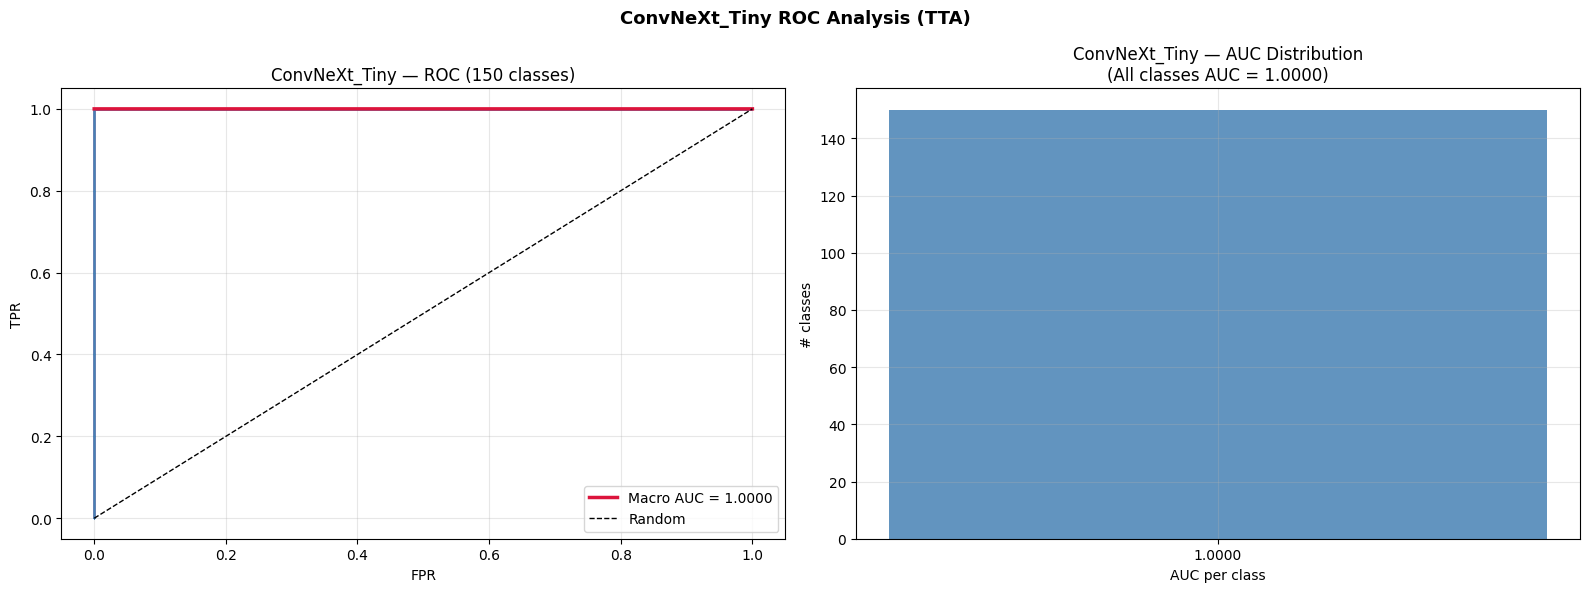

Saved: Outputs/PalmVein_V2/roc/ConvNeXt_Tiny_roc.png  |  Macro AUC: 1.0000


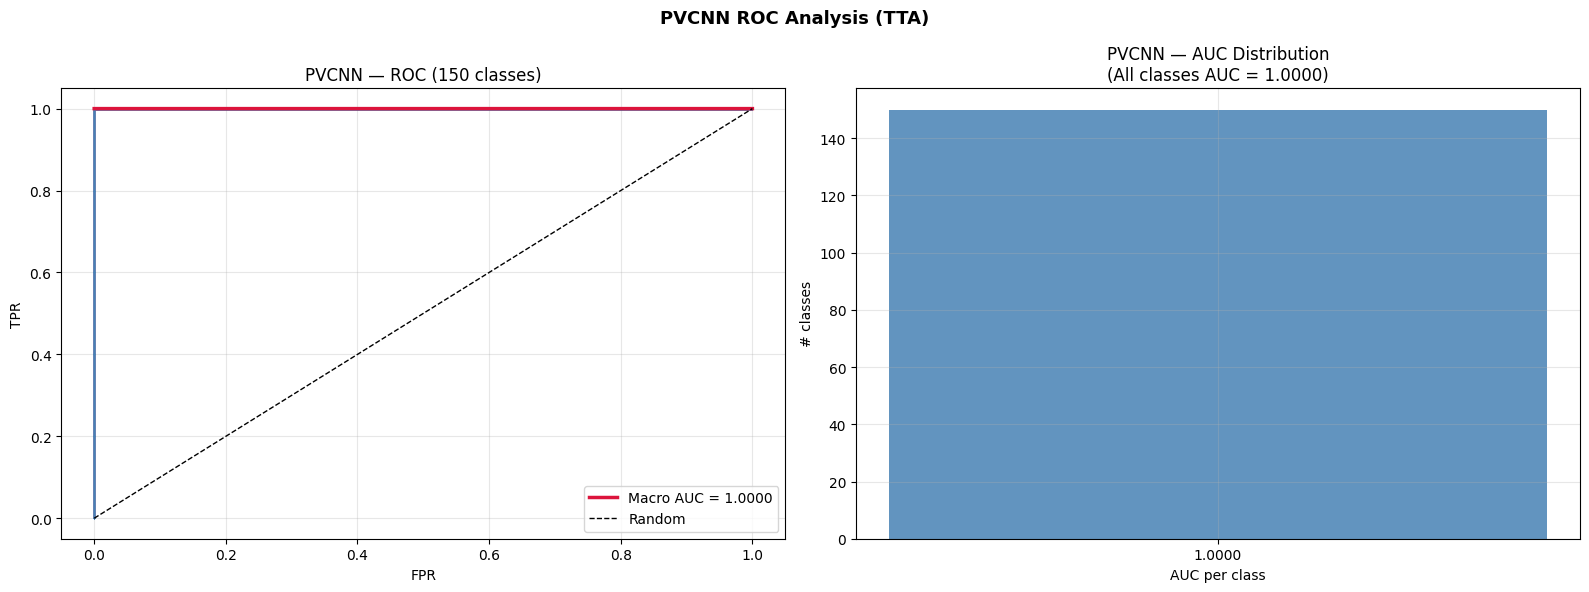

Saved: Outputs/PalmVein_V2/roc/PVCNN_roc.png  |  Macro AUC: 1.0000


In [60]:
for name, (y_true, _, _, _, y_prob_tta) in results.items():
    y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(NUM_CLASSES):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], y_prob_tta[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    all_fpr  = np.unique(np.concatenate([fpr[i] for i in range(NUM_CLASSES)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(NUM_CLASSES):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= NUM_CLASSES
    macro_auc = auc(all_fpr, mean_tpr)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for i in range(NUM_CLASSES):
        axes[0].plot(fpr[i], tpr[i], alpha=0.08, linewidth=0.8, color='steelblue')
    axes[0].plot(all_fpr, mean_tpr, 'crimson', linewidth=2.5,
                 label=f'Macro AUC = {macro_auc:.4f}')
    axes[0].plot([0,1],[0,1], 'k--', linewidth=1, label='Random')
    axes[0].set_title(f'{name} — ROC ({NUM_CLASSES} classes)')
    axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
    axes[0].legend(loc='lower right'); axes[0].grid(True, alpha=0.3)

    # ── AUC histogram — handle case where all values are identical ───────────
    auc_vals = [roc_auc[i] for i in range(NUM_CLASSES)]
    auc_min, auc_max = min(auc_vals), max(auc_vals)

    if auc_max - auc_min < 1e-6:
        # All AUC values identical — show bar chart instead
        axes[1].bar([f'{auc_min:.4f}'], [NUM_CLASSES], color='steelblue', alpha=0.85)
        axes[1].set_title(f'{name} — AUC Distribution\n(All classes AUC = {auc_min:.4f})')
    else:
        n_bins = min(20, len(set([round(v, 4) for v in auc_vals])))
        axes[1].hist(auc_vals, bins=max(1, n_bins),
                     color='steelblue', edgecolor='white', alpha=0.85)
        axes[1].axvline(macro_auc, color='crimson', linewidth=2,
                        label=f'Macro AUC = {macro_auc:.4f}')
        axes[1].legend()
        axes[1].set_title(f'{name} — AUC Distribution')

    axes[1].set_xlabel('AUC per class'); axes[1].set_ylabel('# classes')
    axes[1].grid(True, alpha=0.3)

    plt.suptitle(f'{name} ROC Analysis (TTA)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    path = f'{OUTPUT_BASE}/roc/{name}_roc.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {path}  |  Macro AUC: {macro_auc:.4f}')

## Cell · Final Comparison Chart

Grouped bar chart comparing Standard vs TTA accuracy for all models + ensemble.  
This is the key results figure for the paper.

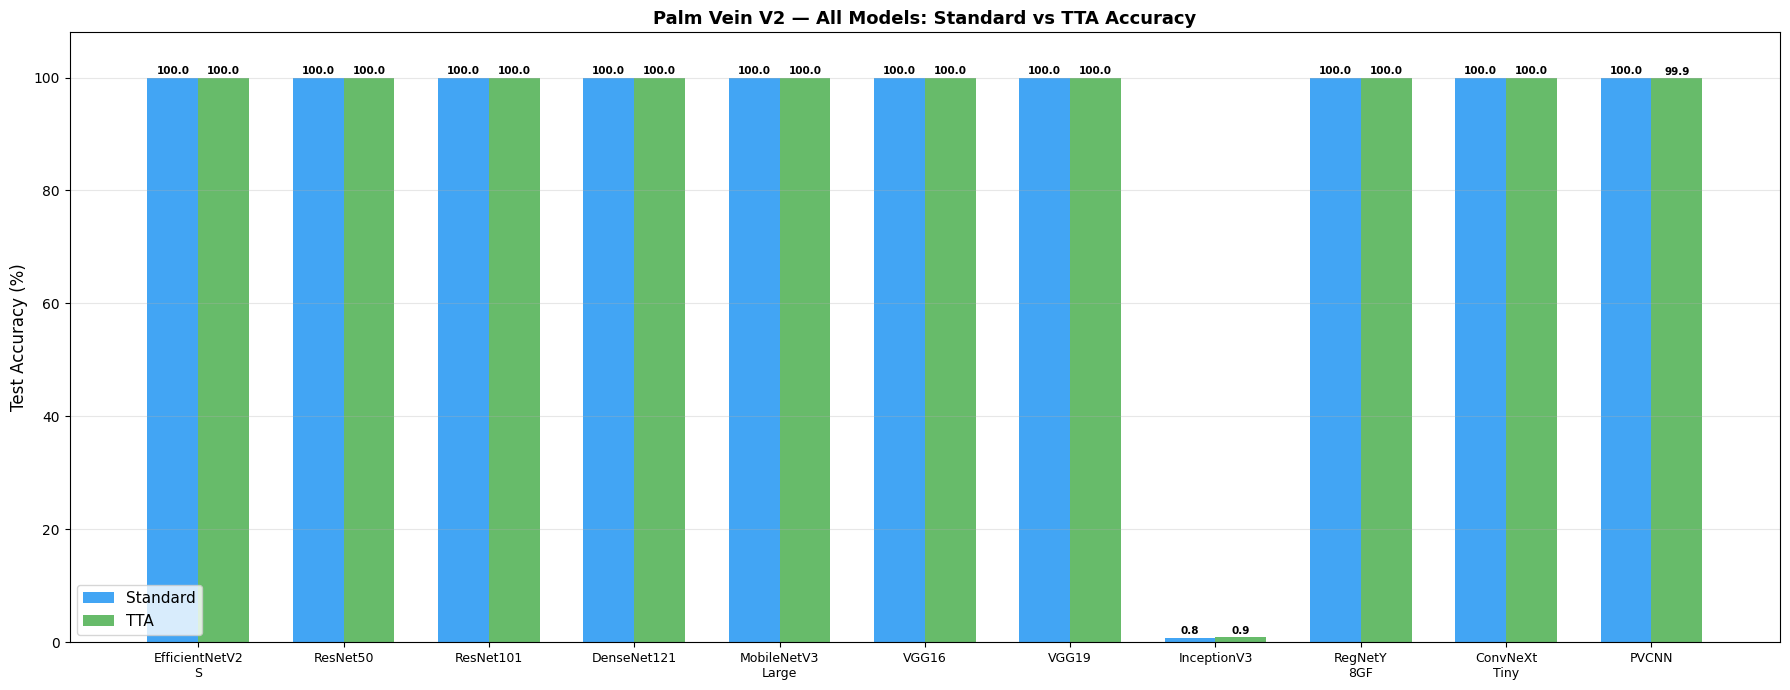

      Model     Mode  Accuracy(%)  Macro F1(%)  Macro Prec(%)  Macro Rec(%)
   ENSEMBLE Standard       100.00       100.00         100.00        100.00
   ENSEMBLE      TTA       100.00       100.00         100.00        100.00
InceptionV3 Standard         0.83         0.12           0.09          1.11
InceptionV3      TTA         0.92         0.16           0.15          1.22
Saved: Outputs/PalmVein_V2/curves/final_comparison.png


In [65]:

# Keep the chart to the actual model set and force a stable order.
# This prevents ENSEMBLE from shifting the visual order and keeps InceptionV3
# in its intended position among the model families.
model_order = [
    'EfficientNetV2_S',
    'ResNet50',
    'ResNet101',
    'DenseNet121',
    'MobileNetV3_Large',
    'VGG16',
    'VGG19',
    'InceptionV3',
    'RegNetY_8GF',
    'ConvNeXt_Tiny',
    'PVCNN',
]

df_chart = df_summary[df_summary['Model'].isin(model_order)].copy()
df_chart['Model'] = pd.Categorical(df_chart['Model'], categories=model_order, ordered=True)
df_chart = df_chart.sort_values(['Model', 'Mode'])
models_list = model_order

x   = np.arange(len(models_list))
w   = 0.35
std_accs = df_chart[df_chart['Mode']=='Standard'].set_index('Model')['Accuracy(%)'].reindex(models_list).values
tta_accs = df_chart[df_chart['Mode']=='TTA'].set_index('Model')['Accuracy(%)'].reindex(models_list).values

fig, ax = plt.subplots(figsize=(18, 7))
bars1 = ax.bar(x - w/2, std_accs, w, label='Standard', color='#2196F3', alpha=0.85)
bars2 = ax.bar(x + w/2, tta_accs, w, label='TTA',      color='#4CAF50', alpha=0.85)

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([m.replace('_', '\n') for m in models_list], fontsize=9)
ax.set_ylabel('Test Accuracy (%)', fontsize=12)
ax.set_title('Palm Vein V2 — All Models: Standard vs TTA Accuracy', fontsize=13, fontweight='bold')
ax.set_ylim(0, 108)
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
path = f'{OUTPUT_BASE}/curves/final_comparison.png'
plt.savefig(path, dpi=150, bbox_inches='tight')
plt.show()
print(df_summary[df_summary['Model'].isin(['InceptionV3', 'ENSEMBLE'])].to_string(index=False))
print(f'Saved: {path}')

 ## Cross-dataset evaluation

Cell 1 — Preprocess & Save

Already preprocessed: 420 images found at F:\Palm Vein Multimodel V2\External\HandVein PLUSVein\HandVein_RL850_Preprocessed


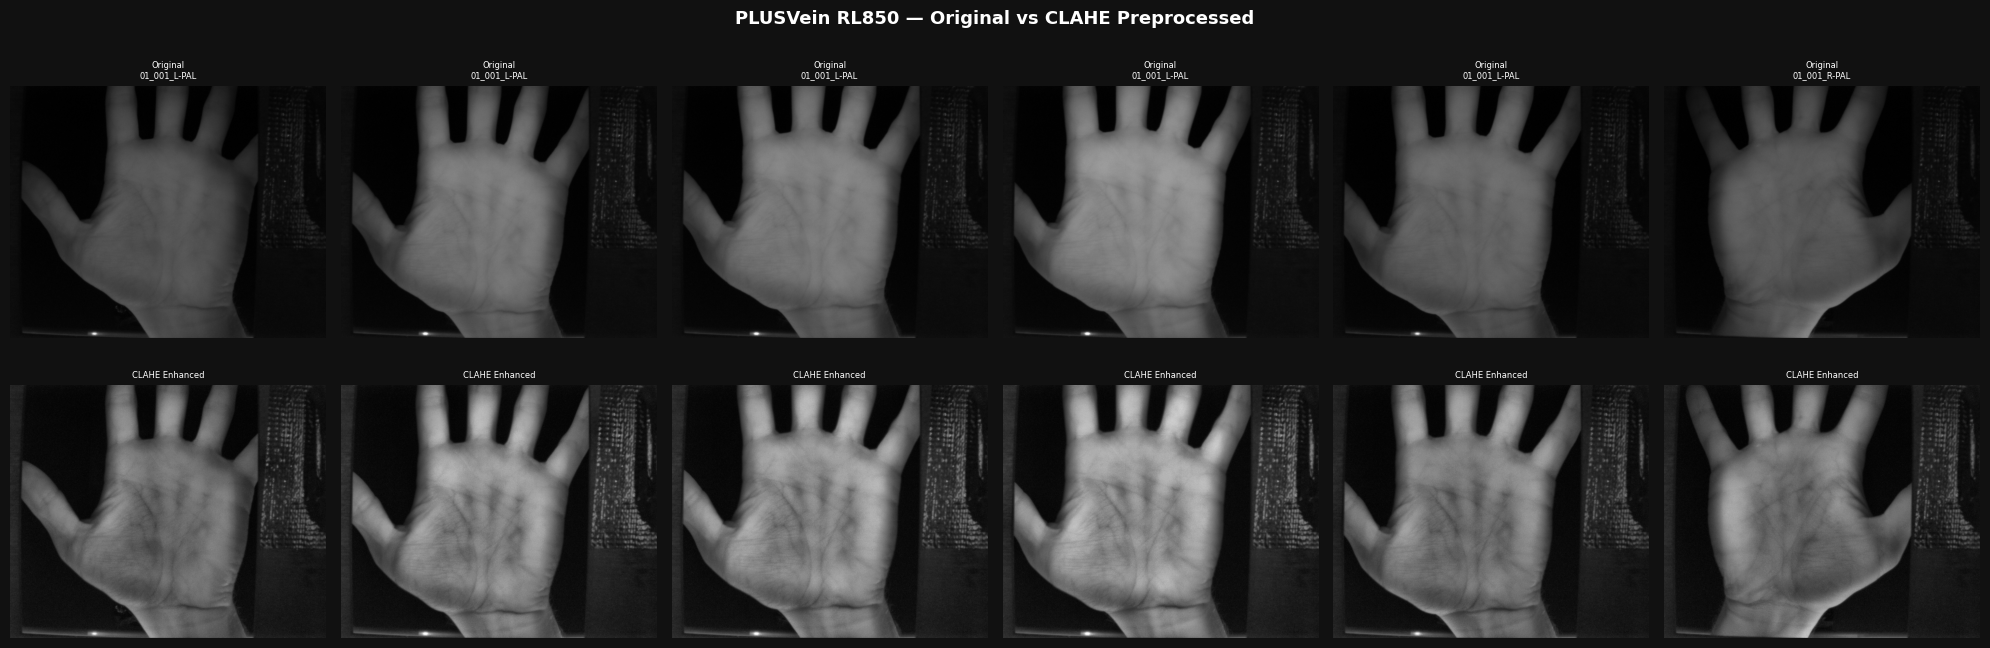

Saved: Outputs/PalmVein_V2/cross_dataset/plusvein_clahe_comparison.png


In [67]:
import cv2
from pathlib import Path
from tqdm import tqdm

# ── Paths ─────────────────────────────────────────────────────────────────────
PLUSVEIN_PATH         = r'F:\Palm Vein Multimodel V2\External\HandVein PLUSVein\HandVein_RL850'
PLUSVEIN_PREPROCESSED = r'F:\Palm Vein Multimodel V2\External\HandVein PLUSVein\HandVein_RL850_Preprocessed'
CROSS_OUTPUT          = f'{OUTPUT_BASE}/cross_dataset'

os.makedirs(PLUSVEIN_PREPROCESSED, exist_ok=True)
os.makedirs(CROSS_OUTPUT, exist_ok=True)

# ── Check if already done ─────────────────────────────────────────────────────
existing = list(Path(PLUSVEIN_PREPROCESSED).glob('*.png'))
if len(existing) > 0:
    print(f'Already preprocessed: {len(existing)} images found at {PLUSVEIN_PREPROCESSED}')
else:
    clahe      = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    all_imgs   = sorted(Path(PLUSVEIN_PATH).glob('*.png'))
    print(f'Preprocessing {len(all_imgs)} PLUSVein RL850 images...')

    skipped = 0
    for img_path in tqdm(all_imgs, desc='CLAHE PLUSVein'):
        img = cv2.imread(str(img_path))
        if img is None:
            skipped += 1
            continue

        # Grayscale → CLAHE → 3-channel (same pipeline as FYODB)
        gray     = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        enhanced = clahe.apply(gray)
        rgb      = cv2.merge([enhanced, enhanced, enhanced])

        dst_path = Path(PLUSVEIN_PREPROCESSED) / img_path.name
        cv2.imwrite(str(dst_path), rgb)

    print(f'Done. Saved: {len(all_imgs)-skipped} | Skipped: {skipped}')
    print(f'Location: {PLUSVEIN_PREPROCESSED}')

# ── Visualize comparison ──────────────────────────────────────────────────────
sample_paths = sorted(Path(PLUSVEIN_PATH).glob('*.png'))[:6]

fig, axes = plt.subplots(2, 6, figsize=(20, 7), facecolor='#111111')
fig.suptitle('PLUSVein RL850 — Original vs CLAHE Preprocessed',
             fontsize=13, fontweight='bold', color='white')

for idx, img_path in enumerate(sample_paths):
    orig     = cv2.imread(str(img_path))
    pre_path = Path(PLUSVEIN_PREPROCESSED) / img_path.name
    pre      = cv2.imread(str(pre_path))

    axes[0][idx].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
    axes[0][idx].set_title(f'Original\n{img_path.stem[:12]}',
                            color='white', fontsize=6)
    axes[0][idx].axis('off')

    axes[1][idx].imshow(cv2.cvtColor(pre, cv2.COLOR_BGR2RGB))
    axes[1][idx].set_title('CLAHE Enhanced', color='white', fontsize=6)
    axes[1][idx].axis('off')

plt.tight_layout()
path = f'{CROSS_OUTPUT}/plusvein_clahe_comparison.png'
plt.savefig(path, dpi=150, bbox_inches='tight', facecolor='#111111')
plt.show()
print(f'Saved: {path}')

Cell 2 — Cross-Dataset Evaluation

PLUSVein RL850 Preprocessed: 420 images | 42 subjects

Running cross-dataset inference...


  EfficientNetV2_S     | Avg Conf: 7.92% | Avg Entropy: 4.332 | Min: 3.66% | Max: 34.00%


  ResNet50             | Avg Conf: 2.80% | Avg Entropy: 4.859 | Min: 0.96% | Max: 13.58%


  ResNet101            | Avg Conf: 4.22% | Avg Entropy: 4.730 | Min: 1.78% | Max: 10.25%


  DenseNet121          | Avg Conf: 3.17% | Avg Entropy: 4.828 | Min: 1.63% | Max: 8.00%


...

  InceptionV3          | Avg Conf: 1.07% | Avg Entropy: 4.992 | Min: 0.89% | Max: 1.61%


  RegNetY_8GF          | Avg Conf: 4.38% | Avg Entropy: 4.789 | Min: 1.54% | Max: 16.83%


  ConvNeXt_Tiny        | Avg Conf: 2.67% | Avg Entropy: 4.855 | Min: 1.66% | Max: 5.57%


C:\Users\SMHC\AppData\Local\Temp\ipykernel_27488\3025377935.py:92: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(models_done, rotation=30, ha='right', color='white', fontsize=8)
C:\Users\SMHC\AppData\Local\Temp\ipykernel_27488\3025377935.py:111: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(models_done, rotation=30, ha='right', color='white', fontsize=8)


  PVCNN                | Avg Conf: 14.91% | Avg Entropy: 3.721 | Min: 5.68% | Max: 51.06%


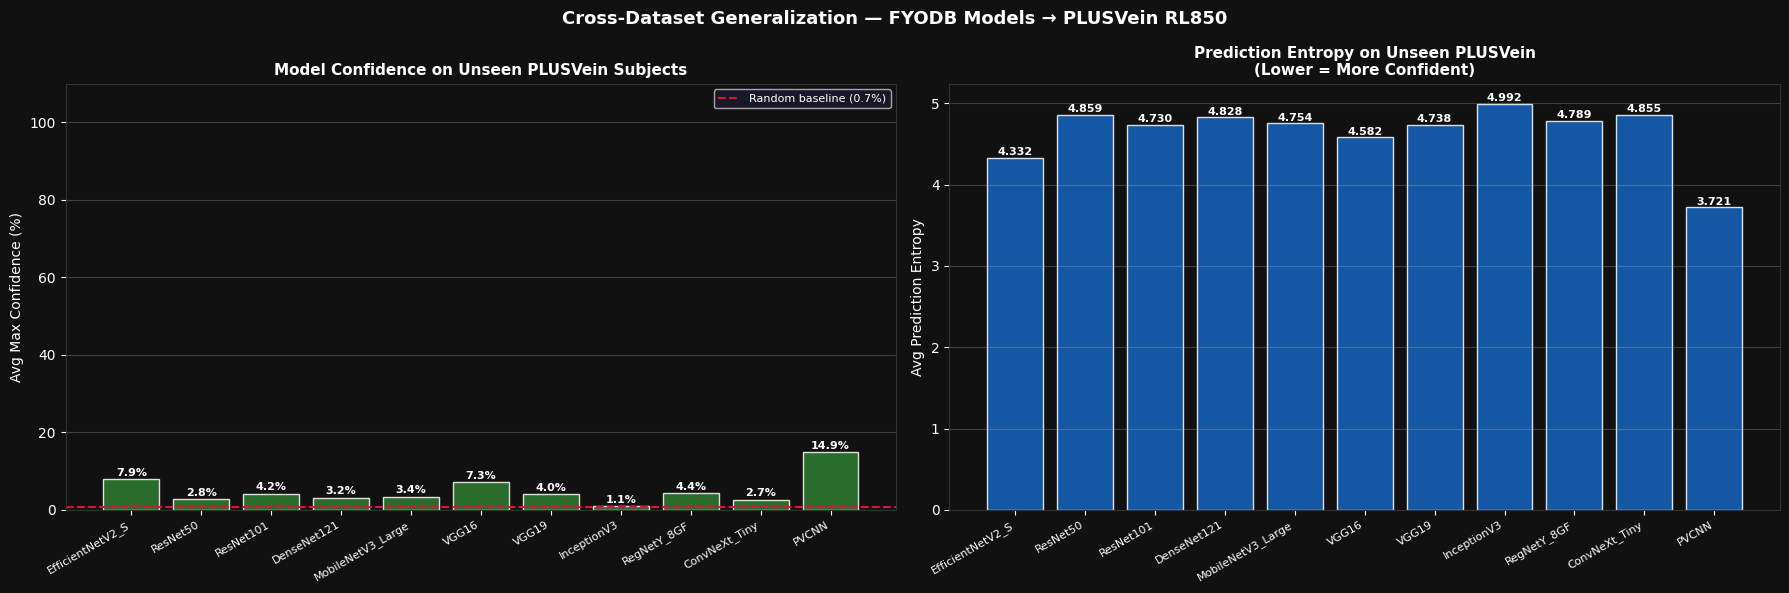

Saved: Outputs/PalmVein_V2/cross_dataset/cross_dataset_confidence.png

Cross-Dataset Summary:
                   Avg Conf (%)  Avg Entropy  Min Conf (%)  Max Conf (%)
Model                                                                   
EfficientNetV2_S       7.921875     4.332031      3.660156     34.000000
ResNet50               2.800781     4.859375      0.959961     13.578125
ResNet101              4.218750     4.730469      1.780273     10.250000
DenseNet121            3.169922     4.828125      1.629883      8.000000
MobileNetV3_Large      3.439453     4.753906      1.570312     17.468750
VGG16                  7.281250     4.582031      2.429688     23.859375
VGG19                  4.039062     4.738281      1.790039     18.062500
InceptionV3            1.070312     4.992188      0.890137      1.610352
RegNetY_8GF            4.378906     4.789062      1.540039     16.828125
ConvNeXt_Tiny          2.669922     4.855469      1.660156      5.570312
PVCNN                 14.90625

c:\Users\SMHC\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\io\formats\format.py:1466: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


In [68]:
import gc
from pathlib import Path

PLUSVEIN_PREPROCESSED = r'F:\Palm Vein Multimodel V2\External\HandVein PLUSVein\HandVein_RL850_Preprocessed'
CROSS_OUTPUT          = f'{OUTPUT_BASE}/cross_dataset'
os.makedirs(CROSS_OUTPUT, exist_ok=True)

# ── Load preprocessed PLUSVein images ────────────────────────────────────────
plusvein_imgs = sorted(Path(PLUSVEIN_PREPROCESSED).glob('*.png'))
subject_ids   = [p.stem.split('_')[1] for p in plusvein_imgs]
unique_subjs  = sorted(set(subject_ids))
print(f'PLUSVein RL850 Preprocessed: {len(plusvein_imgs)} images | {len(unique_subjs)} subjects')

# ── Transforms ────────────────────────────────────────────────────────────────
cross_transform_224 = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

cross_transform_299 = T.Compose([
    T.Resize((299, 299)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def load_plusvein_image(img_path, size=224):
    img = Image.open(img_path).convert('RGB')
    tfm = cross_transform_299 if size == 299 else cross_transform_224
    return tfm(img)

# ── Inference on all models ───────────────────────────────────────────────────
CROSS_MODELS = ['EfficientNetV2_S', 'ResNet50', 'ResNet101',
                'DenseNet121', 'MobileNetV3_Large', 'VGG16',
                'VGG19', 'InceptionV3', 'RegNetY_8GF', 'ConvNeXt_Tiny', 'PVCNN']

cross_results = {}
print('\nRunning cross-dataset inference...')
print('='*60)

for name in CROSS_MODELS:
    if name not in trained_models:
        print(f'  Skipping {name} — not loaded')
        continue

    model = trained_models[name]
    model.eval()
    size  = 299 if name == 'InceptionV3' else 224

    confidences, entropies, top_preds = [], [], []

    with torch.no_grad():
        for img_path in tqdm(plusvein_imgs, desc=f'{name}', leave=False):
            try:
                inp = load_plusvein_image(img_path, size=size).unsqueeze(0).to(DEVICE)
                with autocast('cuda'):
                    logits = model(inp)
                probs = torch.softmax(logits.squeeze(0), dim=0).cpu().numpy()
                confidences.append(probs.max())
                entropies.append(-np.sum(probs * np.log(probs + 1e-10)))
                top_preds.append(probs.argmax())
            except Exception as e:
                print(f'  Error {img_path.name}: {e}')

    cross_results[name] = {
        'confidences': np.array(confidences),
        'entropies':   np.array(entropies),
        'top_preds':   np.array(top_preds),
    }
    print(f'  {name:20s} | Avg Conf: {np.mean(confidences)*100:.2f}% '
          f'| Avg Entropy: {np.mean(entropies):.3f} '
          f'| Min: {np.min(confidences)*100:.2f}% '
          f'| Max: {np.max(confidences)*100:.2f}%')

    torch.cuda.empty_cache()
    gc.collect()

# ── Chart: Confidence + Entropy ───────────────────────────────────────────────
models_done = list(cross_results.keys())
avg_conf    = [cross_results[n]['confidences'].mean() * 100 for n in models_done]
avg_ent     = [cross_results[n]['entropies'].mean()         for n in models_done]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), facecolor='#111111')

# Left: Confidence
axes[0].set_facecolor('#111111')
bars = axes[0].bar(models_done, avg_conf, color='#2E7D32', alpha=0.85, edgecolor='white')
for bar, val in zip(bars, avg_conf):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', va='bottom',
                 color='white', fontsize=8, fontweight='bold')
axes[0].set_xticklabels(models_done, rotation=30, ha='right', color='white', fontsize=8)
axes[0].set_ylabel('Avg Max Confidence (%)', color='white')
axes[0].set_title('Model Confidence on Unseen PLUSVein Subjects',
                  color='white', fontsize=11, fontweight='bold')
axes[0].tick_params(colors='white')
axes[0].set_ylim(0, 110)
axes[0].axhline(100/NUM_CLASSES, color='crimson', linewidth=1.5,
                linestyle='--', label=f'Random baseline ({100/NUM_CLASSES:.1f}%)')
axes[0].legend(facecolor='#1a1a2e', labelcolor='white', fontsize=8)
axes[0].grid(True, axis='y', alpha=0.3)
for spine in axes[0].spines.values(): spine.set_edgecolor('#333333')

# Right: Entropy
axes[1].set_facecolor('#111111')
bars2 = axes[1].bar(models_done, avg_ent, color='#1565C0', alpha=0.85, edgecolor='white')
for bar, val in zip(bars2, avg_ent):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.3f}', ha='center', va='bottom',
                 color='white', fontsize=8, fontweight='bold')
axes[1].set_xticklabels(models_done, rotation=30, ha='right', color='white', fontsize=8)
axes[1].set_ylabel('Avg Prediction Entropy', color='white')
axes[1].set_title('Prediction Entropy on Unseen PLUSVein\n(Lower = More Confident)',
                  color='white', fontsize=11, fontweight='bold')
axes[1].tick_params(colors='white')
axes[1].grid(True, axis='y', alpha=0.3)
for spine in axes[1].spines.values(): spine.set_edgecolor('#333333')

plt.suptitle('Cross-Dataset Generalization — FYODB Models → PLUSVein RL850',
             fontsize=13, fontweight='bold', color='white')
plt.tight_layout()
path = f'{CROSS_OUTPUT}/cross_dataset_confidence.png'
plt.savefig(path, dpi=150, bbox_inches='tight', facecolor='#111111')
plt.show()
print(f'Saved: {path}')

# ── Summary table ─────────────────────────────────────────────────────────────
cross_summary = pd.DataFrame({
    'Model':        models_done,
    'Avg Conf (%)': [round(v, 2) for v in avg_conf],
    'Avg Entropy':  [round(cross_results[n]['entropies'].mean(), 4) for n in models_done],
    'Min Conf (%)': [round(cross_results[n]['confidences'].min()*100, 2) for n in models_done],
    'Max Conf (%)': [round(cross_results[n]['confidences'].max()*100, 2) for n in models_done],
}).set_index('Model')

cross_summary.to_csv(f'{CROSS_OUTPUT}/cross_dataset_summary.csv')
print('\nCross-Dataset Summary:')
print(cross_summary.to_string())